## ДЗ №1. Метрики и простейшие алгоритмы рекомендаций

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from tqdm.auto import tqdm
from typing import List, Optional
from metric_tests import run_tests
import time
import warnings
from scipy import sparse as sps

warnings.filterwarnings('ignore')
%matplotlib inline

## О задании

В этой работе мы посмотрим на то, как работают самые простые модели для рекомендаций. Как правило, они не требуют построения специальных моделей, но даже так оказываются полезны в качестве бейзлайна. Попробуем сделать предсказания с помощью EASE. Это тоже довольно простой подход, но не стоит забывать, что сложные модели могут оказаться не лучшим выбором в условиях большого количества данных. Посчитаем метрики, построим графики и подумаем, насколько хорошо эти модели вообще решают поставленную задачу.

Мы будем работать с датасетом по рекомендации фильмов от Kion MTS, который был дан для соревнования. Сперва нужно его предобработать, эта часть повторяет то, что было на семинаре. 

Датасет необходимо скачать: https://ods.ai/competitions/competition-recsys-21/data

Оттуда нужны файлы `interactions.csv` и `items.csv`

Каждое задание весит **1 балл**, если выполнено полностью и без ошибок, **0 баллов** ставится при наличии хотя бы 1 ошибки. Максимальная оценка - **10 баллов**. Шаблоны функций и классов можно менять по своему усмотрению.

In [2]:
# Данные соревнования МТС (https://ods.ai/competitions/competition-recsys-21/data): interactions.csv и items.csv.
# Если их ещё нет в data/kion/, скачиваем (те же файлы, что на странице соревнования).
import os, urllib.request
os.makedirs('data/kion', exist_ok=True)
for name, url in [('interactions.csv', 'https://storage.yandexcloud.net/datasouls-ods/materials/04adaecc/interactions.csv'),
                  ('items.csv', 'https://storage.yandexcloud.net/datasouls-ods/materials/f90231b6/items.csv')]:
    if not os.path.exists(os.path.join('data/kion', name)):
        urllib.request.urlretrieve(url, os.path.join('data/kion', name))
df = pd.read_csv('data/kion/interactions.csv').iloc[:-1]
df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [3]:
df['last_watch_dt'] = (pd.to_datetime(df['last_watch_dt']) - pd.to_datetime(df['last_watch_dt']).min())
df['last_watch_dt'] = df.last_watch_dt.apply(lambda x: int(str(x).split()[0]))
df.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
2804782,1055479,496,100,189779,10.0
4882073,587285,4495,118,6396,100.0
2573277,707069,7107,64,3,0.0
4360733,482300,7424,133,1483,26.0
1886304,1034881,12114,59,158,3.0


Сделаем разбиение по времени

<Axes: >

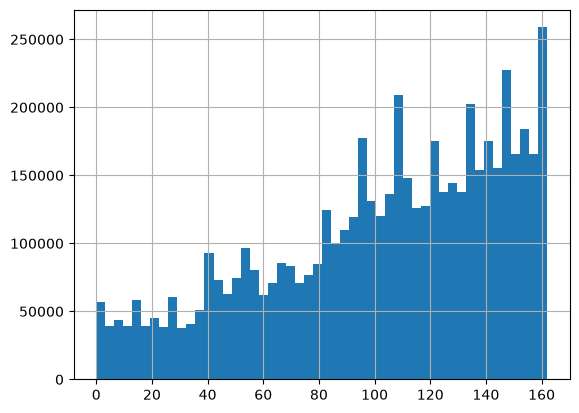

In [4]:
df.last_watch_dt.hist(bins=50)

In [5]:
train_df = df.loc[(df.last_watch_dt < 160-7)].copy()
test_df = df.loc[(df.last_watch_dt >= 160-7)].copy()

train_users = train_df.user_id.unique()
test_users = test_df.user_id.unique()

all_included = np.intersect1d(train_users, test_users)

print('число людей и там и там: ', all_included.shape[0])
print('число людей всего:', train_users.shape[0])

число людей и там и там:  134670
число людей всего: 880449


In [6]:
len(set(test_users) - set(train_users)) / len(test_users)

0.37768022181146027

И переведём всё к соединённому датасету:

In [7]:
n_users = 10000

np.random.seed(42)   # фиксируем выборку пользователей для воспроизводимости
all_included = np.random.choice(all_included, size=n_users, replace=False)

train_df = train_df.loc[train_df.user_id.isin(all_included)].copy()
test_df = test_df.loc[test_df.user_id.isin(all_included)].copy()

assert train_df.last_watch_dt.max() < test_df.last_watch_dt.min()
assert train_df.user_id.nunique() == n_users
assert test_df.user_id.nunique() == n_users

In [8]:
train_df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
77,222359,11237,4,1714,31.0
139,447592,1241,126,127,3.0
160,59968,3734,146,9445,100.0
204,413440,7310,132,1,0.0
293,1011979,146,100,2128,32.0


In [9]:
train_grouped = train_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                 x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
train_grouped.rename({0:'train_interactions'}, axis=1, inplace=True)

test_grouped = test_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                         x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
test_grouped.rename({0:'test_interactions'}, axis=1, inplace=True)

train_grouped.head()

,user_id,train_interactions
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]"
1,299,"[(1154, 1), (3208, 40), (12671, 40), (16390, 4..."
2,571,"[(7149, 0), (10169, 5), (5931, 11), (4606, 11)..."
3,684,"[(11237, 36), (3309, 42), (7417, 42), (5658, 4..."
4,696,"[(8636, 71), (14741, 71), (9996, 72), (14, 73)..."


In [10]:
joined = train_grouped.merge(test_grouped)
joined.head()

,user_id,train_interactions,test_interactions
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]"
1,299,"[(1154, 1), (3208, 40), (12671, 40), (16390, 4...","[(10440, 153)]"
2,571,"[(7149, 0), (10169, 5), (5931, 11), (4606, 11)...","[(4567, 156), (3071, 157), (14461, 159), (212,..."
3,684,"[(11237, 36), (3309, 42), (7417, 42), (5658, 4...","[(341, 162)]"
4,696,"[(8636, 71), (14741, 71), (9996, 72), (14, 73)...","[(8171, 154)]"


In [11]:
np.random.seed(777)

class Random:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        items = set()
        for _, row in df.iterrows():
            for item, _ in row[col]:
                items.add(item)

        self.items = list(items)
        self.trained = True

    def predict(self, df, topn=10):
        assert self.trained
        return [np.random.choice(self.items, replace=False, size=topn)]*len(df)


random = Random()
random.fit(joined)

joined['random_recs'] = random.predict(joined, topn=3)
joined.head()

,user_id,train_interactions,test_interactions,random_recs
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[548, 3343, 8793]"
1,299,"[(1154, 1), (3208, 40), (12671, 40), (16390, 4...","[(10440, 153)]","[548, 3343, 8793]"
2,571,"[(7149, 0), (10169, 5), (5931, 11), (4606, 11)...","[(4567, 156), (3071, 157), (14461, 159), (212,...","[548, 3343, 8793]"
3,684,"[(11237, 36), (3309, 42), (7417, 42), (5658, 4...","[(341, 162)]","[548, 3343, 8793]"
4,696,"[(8636, 71), (14741, 71), (9996, 72), (14, 73)...","[(8171, 154)]","[548, 3343, 8793]"


**Задание №1. Метрики и бейзлайны**

Добавьте реализацию метрик AP, RR, HR, их усреднённые версии по $U$ мы посчитаем ниже, если следовать коду с семинара, поэтому формулы немного отличаются. За имплементацию с циклами балл будет снижаться, векторизуйте! ( ͡° ͜ʖ ͡°)

$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$
p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)
$$
$$
RR@k = \dfrac{1}{\text{rank}_i@k}
$$
$$
HR@k = [\exists \ y_i = 1 \ \text{among k preds}]
$$


*   $n_u$ - число айтемов, с которыми взаимодействовал юзер $u$
*   $y_i$ - релевантно ли $i$-ое предсказание, $y_i \in \{0,1\}$
* $\text{rank}_i@k$ - позиция первого релеваннтого айтема среди первых $k$ предсказаний
* HR@k - среди первых $k$ предсказаний есть хотя бы одно релевантное

Считайте, что если `topn` не задано, то берётся всегда $n_u$. 

In [12]:
def _relevance(gt_items, predictions, topn):
    """Вектор r_u(i) для первых k предсказаний; k = n_u, если topn не задан."""
    k = len(gt_items) if topn is None else topn
    preds = np.asarray(predictions)[:k]
    rel = np.isin(preds, np.asarray(gt_items)).astype(float)
    return rel, k


def ap_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    if len(gt_items) == 0:
        return 0.0
    rel, k = _relevance(gt_items, predictions, topn)
    if rel.size == 0:
        return 0.0
    precision_at_i = np.cumsum(rel) / np.arange(1, rel.size + 1)      # p_u@i для i = 1..k
    return float((rel * precision_at_i).sum() / min(k, len(gt_items)))

def rr_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    rel, _ = _relevance(gt_items, predictions, topn)
    if not rel.any():
        return 0.0
    return float(1.0 / (np.argmax(rel) + 1))                           # позиция первого релевантного

def hr_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    rel, _ = _relevance(gt_items, predictions, topn)
    return float(rel.any())

Для вашего удобства в файле `metric_tests.py` есть тесты, но хардкодить их, разумеется, не стоит. 

*Примечание:* исходного файла `metric_tests.py` из материалов курса не было, поэтому тесты в `metric_tests.py` написаны самостоятельно — строго по формулам из условия (12 случаев, ожидаемые значения посчитаны вручную, см. комментарии в файле).

In [13]:
run_tests(ap_metric, rr_metric, hr_metric)

Все тесты пройдены: 12 случаев x 3 метрики


В следующей ячейке код, который считает и усредняет метрики по юзерам. Он взят с семинара, при желании можно его тоже модифицировать, например, векторизовать. 

In [14]:
def evaluate_recommender(df, model_preds, gt_col='test_interactions', topn=None):

    metric_values = []

    for gt, predictions in zip(df[gt_col], df[model_preds]):
        gt_items = [x[0] for x in gt]

        ap = ap_metric(gt_items, predictions, topn)
        rr = rr_metric(gt_items, predictions, topn)
        hr = hr_metric(gt_items, predictions, topn)

        metric_values.append((ap, rr, hr))

    return {'map': np.mean([x[0] for x in metric_values]),
            'mrr': np.mean([x[1] for x in metric_values]),
            'hr': np.mean([x[2] for x in metric_values])}

In [15]:
# Векторизованный расчёт кривых MAP@k / MRR@k / HR@k сразу для многих k (нужно в заданиях 2, 3, 7–9).
# Формулы те же, что в ap_metric / rr_metric / hr_metric с topn=k — ниже проверка на совпадение.
def relevance_matrix(df, pred_col, gt_col='test_interactions', max_k=100):
    R = np.zeros((len(df), max_k))
    n_u = np.zeros(len(df))
    for row, (gt, preds) in enumerate(zip(df[gt_col], df[pred_col])):
        gt_set = {x[0] for x in gt}
        p = list(preds)[:max_k]
        R[row, :len(p)] = [item in gt_set for item in p]
        n_u[row] = len(gt_set)
    return R, n_u


def metric_curves(df, pred_col, ks=range(1, 101), gt_col='test_interactions'):
    ks = list(ks)
    R, n_u = relevance_matrix(df, pred_col, gt_col, max_k=max(ks))
    precision = np.cumsum(R, axis=1) / np.arange(1, R.shape[1] + 1)
    ap_cum = np.cumsum(R * precision, axis=1)
    first_hit = np.where(R.any(axis=1), R.argmax(axis=1) + 1, np.inf)
    rows = []
    for k in ks:
        rows.append({'k': k,
                     'map': (ap_cum[:, k - 1] / np.minimum(k, n_u)).mean(),
                     'mrr': np.where(first_hit <= k, 1 / first_hit, 0).mean(),
                     'hr': (first_hit <= k).mean()})
    return pd.DataFrame(rows).set_index('k')

Если вы всё сделали правильно, рандомные предсказания должны дать хоть какое-то качество, но не очень большое.

In [16]:
evaluate_recommender(joined, model_preds='random_recs')

{'map': np.float64(8.98611111111111e-05),
 'mrr': np.float64(0.0004333333333333333),
 'hr': np.float64(0.0007)}

In [17]:
class TopPopular:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        counts = {}
        for _, row in df.iterrows():
            for item, _ in row[col]:
                if item in counts:
                    counts[item] += 1
                else:
                    counts[item] = 1

        counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

        self.recommenations = [x[0] for x in counts]
        self.trained = True

    def predict(self, df, topn=10)  -> List[np.ndarray]:

        assert self.trained
        return [self.recommenations[:topn]]*len(df)


toppop = TopPopular()
toppop.fit(joined)

joined['toppopular_recs'] = toppop.predict(joined)
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
1,299,"[(1154, 1), (3208, 40), (12671, 40), (16390, 4...","[(10440, 153)]","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
2,571,"[(7149, 0), (10169, 5), (5931, 11), (4606, 11)...","[(4567, 156), (3071, 157), (14461, 159), (212,...","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
3,684,"[(11237, 36), (3309, 42), (7417, 42), (5658, 4...","[(341, 162)]","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."
4,696,"[(8636, 71), (14741, 71), (9996, 72), (14, 73)...","[(8171, 154)]","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ..."


Самые популярные предсказания должны показать более высокое качество.

In [18]:
evaluate_recommender(joined, model_preds='toppopular_recs')

{'map': np.float64(0.03590145867259081),
 'mrr': np.float64(0.08288174603174603),
 'hr': np.float64(0.1394)}

In [19]:
# проверка: векторизованные кривые совпадают с поэлементными метриками
for k in [1, 5, 10]:
    vec = metric_curves(joined, 'toppopular_recs', ks=[k]).loc[k].to_dict()
    loop = evaluate_recommender(joined, 'toppopular_recs', topn=k)
    assert all(np.isclose(vec[m], loop[m]) for m in ['map', 'mrr', 'hr']), (k, vec, loop)
print('OK: векторизованные метрики совпадают с ap_metric / rr_metric / hr_metric')

OK: векторизованные метрики совпадают с ap_metric / rr_metric / hr_metric


**Задание №2. Рекомендации в окне**

Здесь необходимо переделать метод рекомендации по популярности так, что популярность считается только за какое-то более свежее временное окно. Под окном подразумевается какой-то временной промежуток, например, ближайший месяц. Соответственно, всё что за его пределами, не учитывается.

In [20]:
class TopPopularWeighted(TopPopular):
    """Популярность считается только по последним min_window дням трейна (окно в днях)."""

    def __init__(self, min_window=2):
        super().__init__()
        self.min_window = min_window

    def fit(self, df, col='train_interactions'):
        last_day = max(t for row in df[col] for _, t in row)
        start_day = last_day - self.min_window + 1          # окно: [last_day - min_window + 1, last_day]

        counts, counts_all = {}, {}
        for row in df[col]:
            for item, t in row:
                counts_all[item] = counts_all.get(item, 0) + 1
                if t >= start_day:
                    counts[item] = counts.get(item, 0) + 1

        in_window = [x[0] for x in sorted(counts.items(), key=lambda x: x[1], reverse=True)]
        # если в коротком окне айтемов меньше, чем нужно, добиваем общей популярностью
        rest = [x[0] for x in sorted(counts_all.items(), key=lambda x: x[1], reverse=True) if x[0] not in counts]
        self.recommenations = in_window + rest
        self.trained = True
        return self

Теперь постройте графики зависимости значений трёх метрик (AP@k, RR@k, HR@k) от размера окна. 

  0%|          | 0/14 [00:00<?, ?it/s]

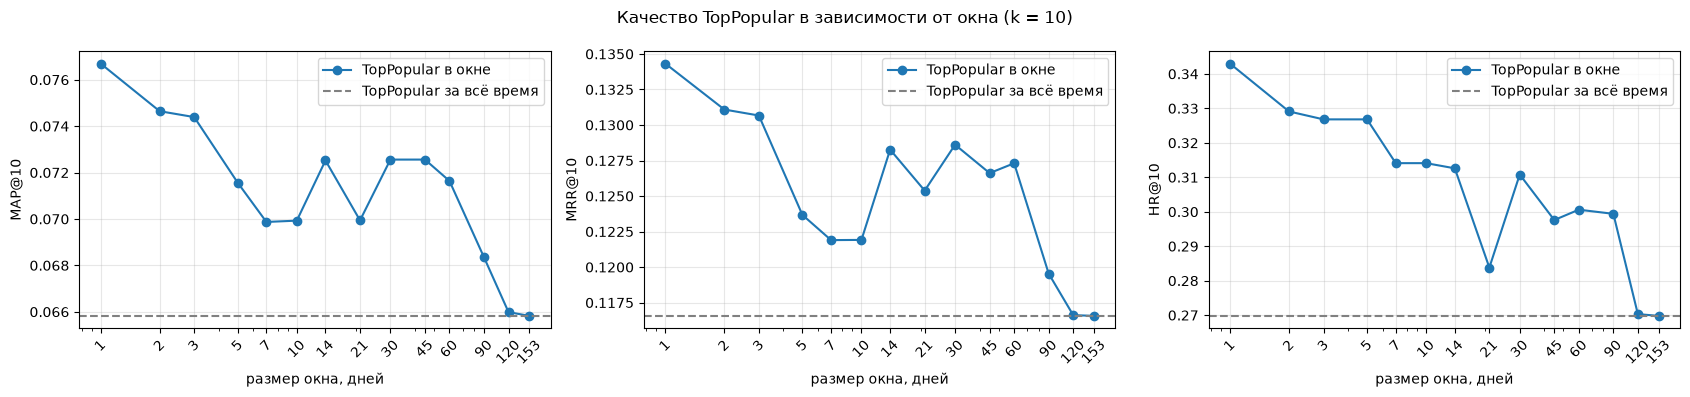

,map,mrr,hr
window,,,
1,0.076699,0.134325,0.3430
2,0.074645,0.131089,0.3291
3,0.074391,0.130667,0.3268
5,0.071561,0.123672,0.3268
7,0.069871,0.121899,0.3141
10,0.069928,0.121913,0.3141
14,0.072521,0.128267,0.3126
21,0.069939,0.125382,0.2838
30,0.072559,0.128613,0.3108


In [21]:
windows = [1, 2, 3, 5, 7, 10, 14, 21, 30, 45, 60, 90, 120, 153]
TOPN = 10
window_results = []
for w in tqdm(windows):
    model = TopPopularWeighted(min_window=w).fit(joined)
    joined['tmp_recs'] = model.predict(joined, topn=100)
    window_results.append({'window': w, **metric_curves(joined, 'tmp_recs', ks=[TOPN]).loc[TOPN].to_dict()})
window_results = pd.DataFrame(window_results).set_index('window')
toppop_ref = metric_curves(joined, 'toppopular_recs', ks=[TOPN]).loc[TOPN]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, m, name in zip(axes, ['map', 'mrr', 'hr'], ['MAP', 'MRR', 'HR']):
    ax.plot(window_results.index, window_results[m], marker='o', label='TopPopular в окне')
    ax.axhline(toppop_ref[m], color='gray', ls='--', label='TopPopular за всё время')
    ax.set_xscale('log'); ax.set_xticks(windows); ax.set_xticklabels(windows, rotation=45)
    ax.set_xlabel('размер окна, дней'); ax.set_ylabel(f'{name}@{TOPN}'); ax.grid(alpha=0.3); ax.legend()
plt.suptitle(f'Качество TopPopular в зависимости от окна (k = {TOPN})'); plt.tight_layout(); plt.show()
window_results

In [22]:
# То же при k = n_u (topn не задан) — чтобы убедиться, что вывод не зависит от выбора k
window_results_nu = []
for w in windows:
    model = TopPopularWeighted(min_window=w).fit(joined)
    joined['tmp_recs'] = model.predict(joined, topn=100)
    window_results_nu.append({'window': w, **evaluate_recommender(joined, 'tmp_recs')})
window_results_nu = pd.DataFrame(window_results_nu).set_index('window')
best_window = int(window_results['map'].idxmax())
print('Лучшее окно по MAP@10:', best_window, 'дней; по MAP@n_u:', int(window_results_nu['map'].idxmax()), 'дней')

# сколько новых айтемов появляется в тесте и насколько топ меняется со временем
top_recent = TopPopularWeighted(min_window=7).fit(joined).recommenations[:10]
top_all = toppop.recommenations[:10]
print('Пересечение топ-10 за 7 дней и за всё время:', len(set(top_recent) & set(top_all)), 'из 10')
window_results_nu

Лучшее окно по MAP@10: 1 дней; по MAP@n_u: 45 дней
Пересечение топ-10 за 7 дней и за всё время: 6 из 10


,map,mrr,hr
window,,,
1,0.041297,0.094373,0.1559
2,0.040555,0.092153,0.1508
3,0.040521,0.092185,0.1509
5,0.036017,0.083597,0.1473
7,0.035877,0.083354,0.1464
10,0.035817,0.083242,0.1458
14,0.040333,0.091635,0.1477
21,0.040586,0.091882,0.1480
30,0.040648,0.091994,0.1486


Подумайте и ответьте, как размер окна влияет на качество рекомендаций. Какое значение наилучшее, есть ли у этого разумное объяснение?

**Ответ:**
* **При k = 10** лучше всего самое короткое окно — **1 день**: MAP@10 ≈ 0.077, MRR@10 ≈ 0.134, HR@10 ≈ 0.343. Хуже всего популярность за весь трейн (153 дня): MAP@10 ≈ 0.066, HR@10 ≈ 0.270. Между 7 и 60 днями держится плато (MAP@10 ≈ 0.070–0.073), от 90 дней качество снижается.
* **При k = n_u** картина шумнее и немонотонная. Все значения MAP лежат в узком коридоре 0.036–0.042:
  * окна 1–3 дня и 14–60 дней примерно равны (≈ 0.040–0.042, формально лучшее — 45 дней);
  * окна 5–10 дней проседают до уровня популярности за весь период (≈ 0.036) — в них попадает другой набор лидеров;
  * окна 90+ дней снова хуже.
* **Однозначный вывод один: очень длинное окно (90+ дней) хуже коротких и средних.** Между коротким и средним выбор зависит от метрики и сильно шумит: выборка — всего 10 000 юзеров, а тестовых айтемов у юзера в среднем около трёх.
* **Объяснение — сильный дрейф популярности в онлайн-кинотеатре.** Тест — это следующие ~10 дней, и смотрят в них в основном то, что в тренде прямо сейчас: свежие премьеры и тайтлы с витрины. Топ-10 за последние 7 дней совпадает с топом за всё время лишь на 6 из 10. Длинное окно тянет вверх прошлые хиты: их уже посмотрели, а интерес к ним угас (паттерн «затухание хита» в задании 4).
* **Практический выбор:** 1–3 дня, если важен верх выдачи (k = 10), или 2–6 недель, если нужна устойчивость к шуму.
* **Оговорка:** окно подбиралось по тестовым метрикам, как в формулировке задания, поэтому оценка лучшего окна оптимистична.

**Задание №3. Метрики и k.**

Постройте зависимость значений MAP@K, MRR@K, HR@K для метода рекомендации по популярности. Возьмите какие-нибудь k, например, от 1 до 100, переберите значения и покажите на линейном графике. 

In [23]:
joined['toppopular_recs'] = toppop.predict(joined, topn=100)

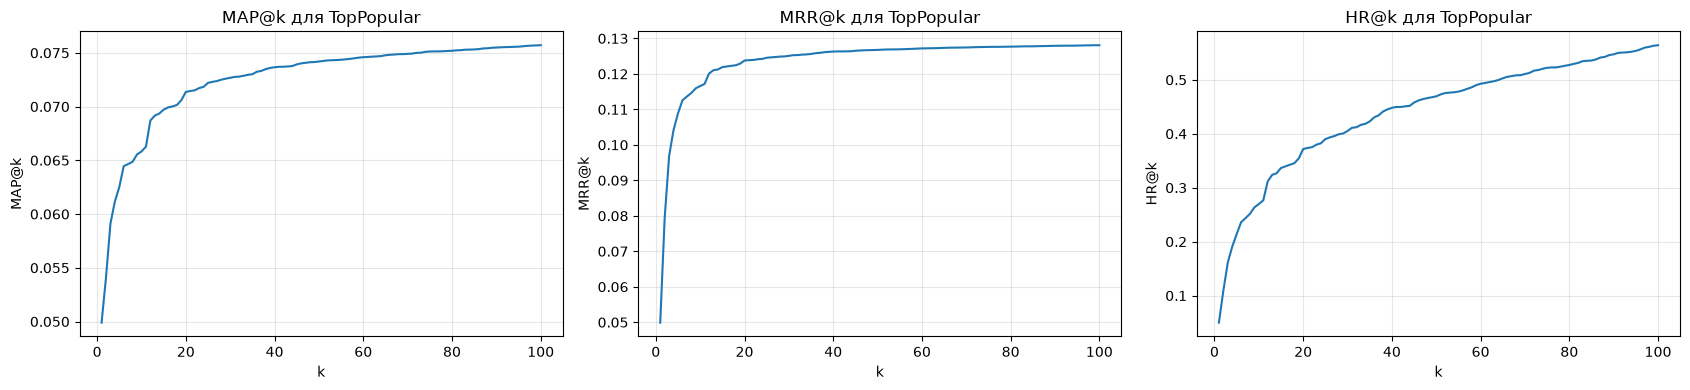

map: монотонно неубывает — False; число убывающих шагов: 1; максимум при k = 100
mrr: монотонно неубывает — True; число убывающих шагов: 0; максимум при k = 100
hr: монотонно неубывает — True; число убывающих шагов: 0; максимум при k = 100


,map,mrr,hr
k,,,
1,0.049900,0.049900,0.0499
2,0.054100,0.079400,0.1089
3,0.059117,0.096833,0.1612
5,0.062523,0.108863,0.2140
10,0.065824,0.116568,0.2698
20,0.071367,0.123771,0.3718
50,0.074196,0.126760,0.4694
100,0.075712,0.128088,0.5642


In [24]:
ks = range(1, 101)
toppop_curves = metric_curves(joined, 'toppopular_recs', ks=ks)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, m, name in zip(axes, ['map', 'mrr', 'hr'], ['MAP@k', 'MRR@k', 'HR@k']):
    ax.plot(toppop_curves.index, toppop_curves[m])
    ax.set_xlabel('k'); ax.set_ylabel(name); ax.set_title(name + ' для TopPopular'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# проверка монотонности
for m in ['map', 'mrr', 'hr']:
    diffs = np.diff(toppop_curves[m].values)
    print(f'{m}: монотонно неубывает — {bool((diffs >= -1e-12).all())}; '
          f'число убывающих шагов: {(diffs < -1e-12).sum()}; максимум при k = {toppop_curves[m].idxmax()}')
toppop_curves.loc[[1, 2, 3, 5, 10, 20, 50, 100]]

count    10000.00
mean         3.14
std          3.86
min          1.00
25%          1.00
50%          2.00
75%          4.00
90%          7.00
99%         19.00
max         76.00


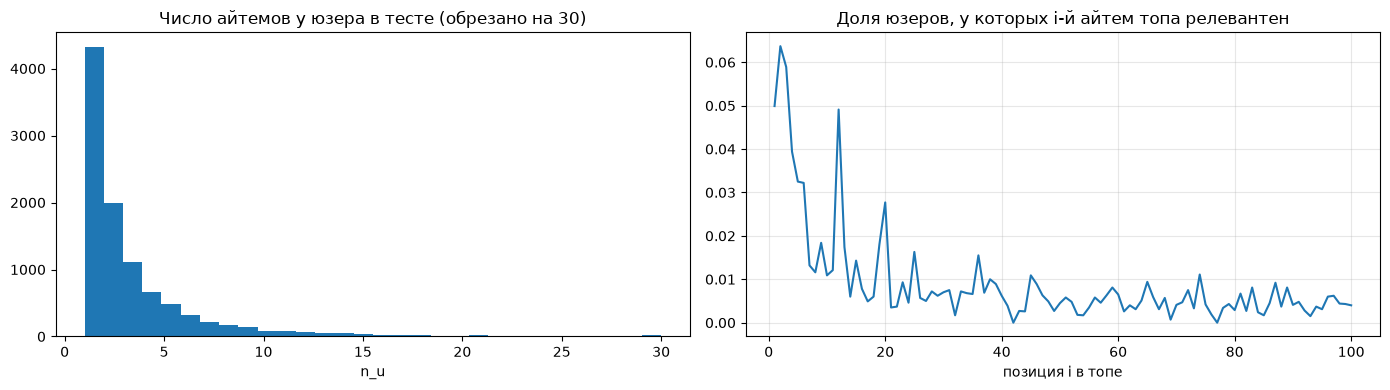

In [25]:
# Дополнительный анализ для вопроса 3.3: сколько айтемов у пользователей в тесте и где в топе находятся попадания
n_test = joined.test_interactions.apply(len)
print(n_test.describe(percentiles=[.25, .5, .75, .9, .99]).round(2).to_string())

R, n_u = relevance_matrix(joined, 'toppopular_recs', max_k=100)
hit_rate_by_position = R.mean(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(n_test.clip(upper=30), bins=30); axes[0].set_title('Число айтемов у юзера в тесте (обрезано на 30)')
axes[0].set_xlabel('n_u')
axes[1].plot(range(1, 101), hit_rate_by_position); axes[1].set_title('Доля юзеров, у которых i-й айтем топа релевантен')
axes[1].set_xlabel('позиция i в топе'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Хорошенько подумайте и ответьте на вопросы ниже.

**3.1 Какие из метрик являются монотонными функциями по top-K? Объясните, почему они являются монотонными?**

**Ответ:** монотонно неубывающие — **HR@k** и **MRR@k** (на графике и в проверке `np.diff` у них нет ни одного убывающего шага).
* HR@k — индикатор «среди первых k есть хотя бы одно попадание». Добавление позиций не может убрать уже найденное попадание, поэтому HR@(k+1) ≥ HR@k.
* RR@k равен 1/rank первого релевантного, если rank ≤ k, и 0 иначе. Пока первое попадание не найдено, RR = 0. Когда k доходит до его позиции, RR становится 1/rank и дальше не меняется. Среднее неубывающих функций тоже не убывает.
* **MAP@k** с нормировкой 1/min(k, n_u) в общем случае **не монотонна**: при k < n_u знаменатель растёт вместе с k. Если новая позиция нерелевантна, числитель не растёт, а знаменатель растёт, и AP падает. При k ≥ n_u знаменатель фиксирован, и AP не убывает. В данных у TopPopular нашёлся один убывающий шаг. Ещё нагляднее это у EASE в задании 7: MAP@1 ≈ 0.093, а MAP@3 ≈ 0.079.

**3.2 Объясните по каждой метрике, как можно интерпретировать её график?**

**Ответ:**
* **HR@k** — вероятность, что пользователь, пролистав ленту на k позиций, встретит хоть что-то интересное. Наклон кривой показывает, сколько «успеха» даёт каждый следующий экран скролла. Кривая вогнутая: первые позиции дают много, дальше отдача убывает. Для TopPopular HR@10 ≈ 0.27, HR@100 ≈ 0.56.
* **MRR@k** — насколько быстро пользователь находит первое релевантное. Это сценарий «один клик»: баннер, первый экран, автоплей. Кривая быстро выходит на плато (≈ 0.12 уже к k = 10–20). Если первое попадание не случилось в начале ленты, глубокий скролл почти ничего не добавляет к MRR — пользователь, скорее всего, уже ушёл.
* **MAP@k** — сколько релевантного в ленте и насколько высоко оно стоит. Сценарий, где пользователь «потребляет» несколько позиций (смотрит подряд). Рост после k ≈ 20 медленный: нижние позиции вносят мало, потому что каждое попадание взвешивается точностью на своей позиции.

**3.3 Как вы думаете, почему графики выглядят именно так?**

**Ответ:**
* TopPopular выдаёт всем один и тот же список. Доля пользователей, у которых i-й айтем топа релевантен, быстро падает с ростом i (правый график): чем ниже айтем в топе, тем менее он популярен в тесте. Отсюда вогнутая форма HR@k и быстрый выход MRR@k на плато.
* У пользователей мало тестовых айтемов: медиана n_u = 2, 75% — не больше 4, у четверти ровно 1. Поэтому знаменатель min(k, n_u) почти сразу перестаёт расти и MAP@k быстро стабилизируется. У пользователей с n_u = 1 MAP@k совпадает с MRR@k.
* Даже при k = 100 HR ≈ 0.56: почти половина пользователей смотрит в тесте только то, чего нет в топ-100 трейна (хвост каталога и новинки периода). Кроме того, TopPopular не убирает уже просмотренное: часть верхних позиций тратится на фильмы, которые пользователь уже видел.
* В общем случае HR@k и MRR@k обязаны не убывать, а MAP@k может и расти, и убывать. Форма кривых зависит от распределения n_u, от концентрации спроса на верхних айтемах (здесь она высокая) и от дрейфа между трейном и тестом.

**Задание №4. Интерпретация рейтингов**

Возьмите названия фильмов/сериалов из `items.csv`, выделите 5 различных сценариев изменения популярности у фильмов, аргументируйте (например, графиком или статистикой) и проинтерпретируейте их (почему популярность для этого фильма меняется так). Обратите внимание, что надо найти именно разные паттерны изменения вероятностей. 

In [26]:
items = pd.read_csv('data/kion/items.csv')[['item_id','title']].copy()
items.head()

,item_id,title
0,10711,Поговори с ней
1,2508,Голые перцы
2,10716,Тактическая сила
3,7868,45 лет
4,16268,Все решает мгновение


Пример:

1917


<Axes: >

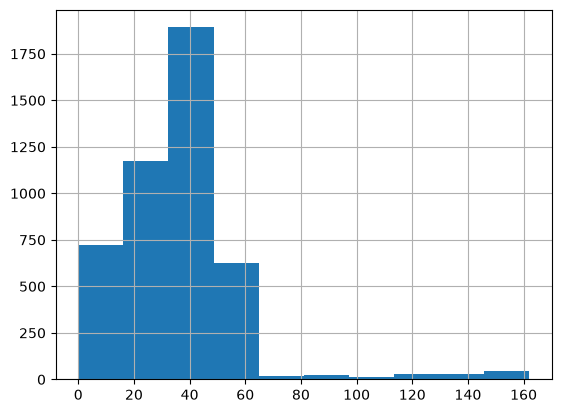

In [27]:
popular_items = df.item_id.value_counts()[:300].index.tolist()
sampled_id = np.random.choice(popular_items)

# это для примера, хотя выцеплять случаи по одному может быть не лучшей идеей
sampled_id = 3402

interactions = df.loc[df.item_id==sampled_id].copy()
name = items.loc[items.item_id==sampled_id].title.values[0]
print(name)
interactions.last_watch_dt.hist()

In [28]:
# «кстати, с какой даты?» — первый день, когда просмотры 1917 упали ниже 10% от среднего за предыдущую неделю
date0 = pd.to_datetime(pd.read_csv('data/kion/interactions.csv', usecols=['last_watch_dt'])['last_watch_dt']).min()
s1917 = interactions.groupby('last_watch_dt').size().reindex(range(df.last_watch_dt.max() + 1), fill_value=0)
prev_week = s1917.rolling(7).mean().shift(1)
drop_day = int(s1917[(prev_week > 20) & (s1917 < 0.1 * prev_week)].index[0])
print(f'резкое падение: день {drop_day} = {(date0 + pd.Timedelta(days=drop_day)).date()}; '
      f'за неделю до этого в среднем {prev_week[drop_day]:.0f} просмотров/день, в этот день {s1917[drop_day]}, '
      f'дальше в среднем {s1917[drop_day + 1:].mean():.1f}/день')

резкое падение: день 54 = 2021-05-06; за неделю до этого в среднем 121 просмотров/день, в этот день 1, дальше в среднем 1.6/день


Фильм 1917 какое-то время набирал популярность, потом видим резкое падение (кстати, с какой даты?). Возможно, это связано с ограничением доступности этого фильма для части пользователей, периодом проката фильма / рекламной кампании или другой причиной. 

Добавьте 5 своих примеров ниже. Опишите, как вы их искали. 

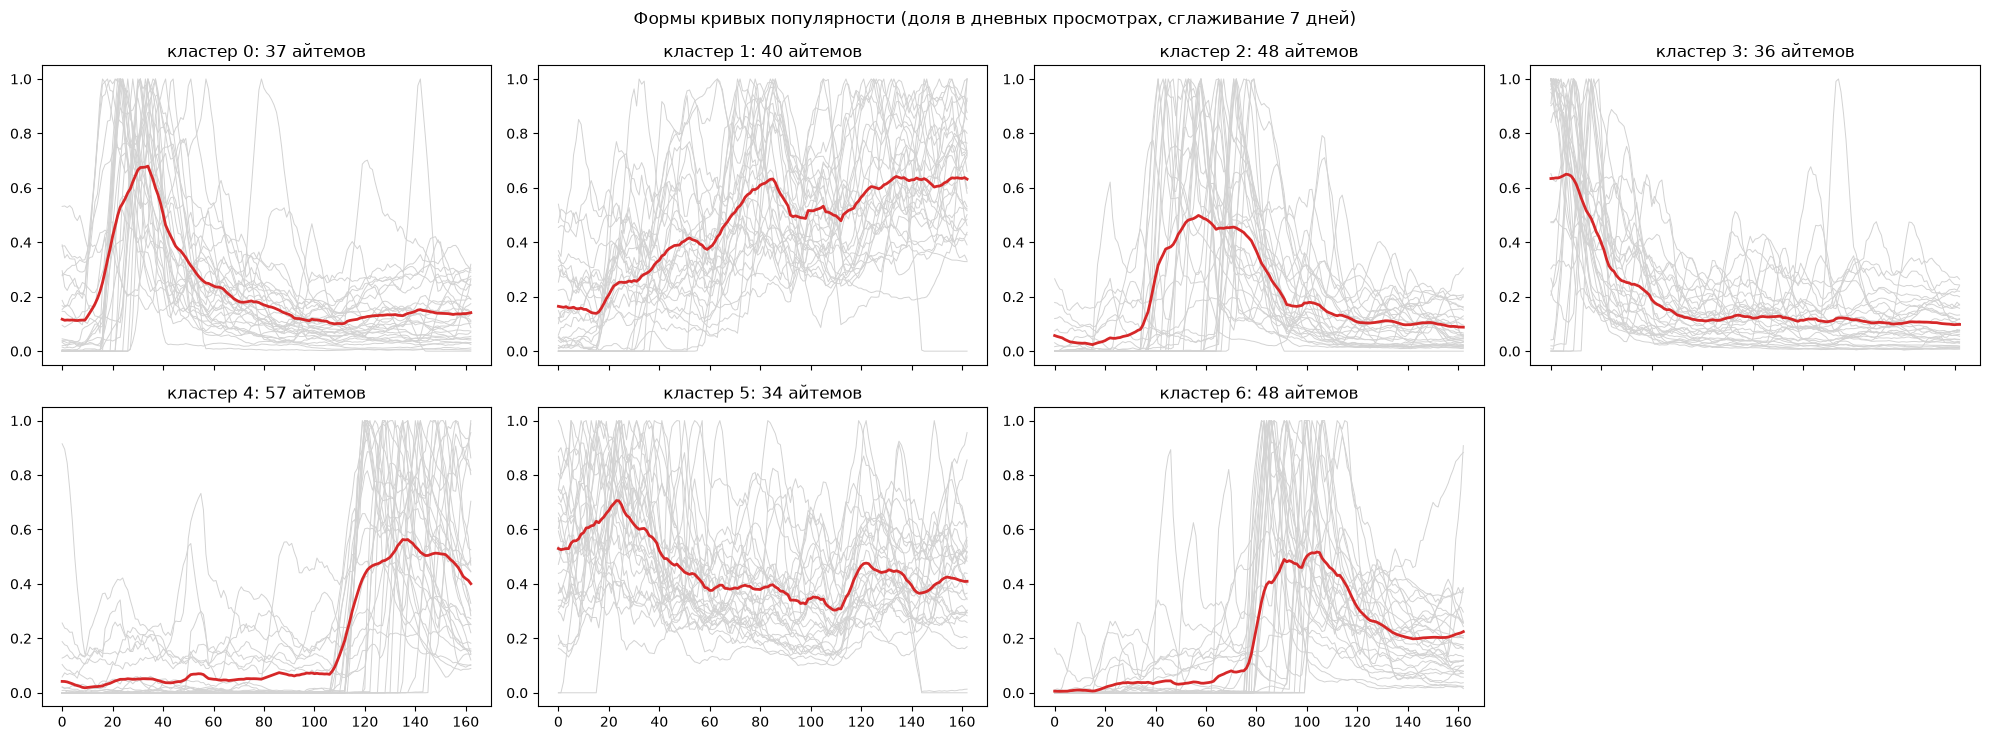

,peak_day,first_day,cv,trend,total_views
cluster,,,,,
0,31.0,0.0,1.02,-0.27,4756.0
1,117.5,0.0,0.55,0.49,5893.0
2,55.5,36.0,1.25,-0.03,5433.5
3,6.5,0.0,1.08,-0.37,4802.0
4,135.0,55.0,1.63,0.53,4749.0
5,26.5,0.0,0.48,-0.19,4386.5
6,93.0,66.0,1.29,0.35,4691.0


In [29]:
# Поиск разных паттернов: берём 300 самых популярных айтемов, строим их долю в дневных просмотрах
# (доля, а не абсолютное число — чтобы убрать общий рост аудитории сервиса), сглаживаем по неделе,
# нормируем каждую кривую к её максимуму и кластеризуем формы кривых KMeans.
from sklearn.cluster import KMeans

items_full = pd.read_csv('data/kion/items.csv')
item_title = dict(zip(items_full.item_id, items_full.title))
item_year = dict(zip(items_full.item_id, items_full.release_year))
item_type = dict(zip(items_full.item_id, items_full.content_type))

top_items = df.item_id.value_counts()[:300].index
daily_total = df.groupby('last_watch_dt').size()
daily = (df[df.item_id.isin(top_items)].groupby(['item_id', 'last_watch_dt']).size()
           .unstack(fill_value=0).reindex(columns=daily_total.index, fill_value=0))
share = daily / daily_total.values                         # доля айтема в дневных просмотрах
smooth = share.T.rolling(7, min_periods=1, center=True).mean().T
shape = smooth.div(smooth.max(axis=1), axis=0)             # форма кривой, максимум = 1

# простые описательные признаки формы
days = np.arange(shape.shape[1])
stats = pd.DataFrame({
    'title': [item_title.get(i, '?') for i in shape.index],
    'type': [item_type.get(i, '?') for i in shape.index],
    'year': [item_year.get(i, np.nan) for i in shape.index],
    'peak_day': shape.values.argmax(axis=1),
    'first_day': (daily.values > 0).argmax(axis=1),
    'last_day': daily.shape[1] - 1 - (daily.values[:, ::-1] > 0).argmax(axis=1),
    'cv': smooth.std(axis=1) / smooth.mean(axis=1),        # насколько «неровная» кривая
    'trend': np.polyfit(days, shape.T.values, 1)[0] * len(days),   # изменение за весь период в долях максимума
    'total_views': df[df.item_id.isin(top_items)].item_id.value_counts().reindex(shape.index).values,
}, index=shape.index)

kmeans = KMeans(n_clusters=7, n_init=20, random_state=42).fit(shape.values)
stats['cluster'] = kmeans.labels_

fig, axes = plt.subplots(2, 4, figsize=(20, 7.5), sharex=True)
for c, ax in zip(range(7), axes.ravel()):
    members = shape.index[stats.cluster == c]
    for i in members[:30]:
        ax.plot(shape.columns, shape.loc[i], color='lightgray', lw=0.7)
    ax.plot(shape.columns, kmeans.cluster_centers_[c], color='tab:red', lw=2)
    ax.set_title(f'кластер {c}: {len(members)} айтемов')
axes.ravel()[-1].axis('off')
plt.suptitle('Формы кривых популярности (доля в дневных просмотрах, сглаживание 7 дней)')
plt.tight_layout(); plt.show()

stats.groupby('cluster')[['peak_day', 'first_day', 'cv', 'trend', 'total_views']].median().round(2)

In [30]:
# Самые типичные представители каждого кластера (ближайшие к центру)
dist = ((shape.values - kmeans.cluster_centers_[stats.cluster.values]) ** 2).sum(axis=1)
stats['dist_to_center'] = dist
reps = stats.sort_values('dist_to_center').groupby('cluster').head(4).sort_values(['cluster', 'dist_to_center'])
reps[['cluster', 'title', 'type', 'year', 'peak_day', 'first_day', 'last_day', 'cv', 'trend', 'total_views']]

,cluster,title,type,year,peak_day,first_day,last_day,cv,trend,total_views
item_id,,,,,,,,,,
15248,0,Родина,series,2011.0,30,21,162,0.966397,-0.192114,3510
1617,0,Форма воды,film,2017.0,31,1,162,1.132932,-0.216221,4233
12463,0,Студентка по вызову,film,2010.0,24,0,141,1.103756,-0.452128,8049
15739,0,Kingsman: Золотое кольцо,film,2017.0,32,0,162,0.835417,-0.208948,3880
8784,1,Скандал,series,2012.0,85,0,162,0.321138,0.421507,3620
565,1,Ледниковый период 3: Эра динозавров,film,2009.0,124,0,162,0.536575,0.644072,3249
9900,1,Без компромиссов,film,2011.0,86,0,162,0.597485,0.614952,4395
2722,1,Один дома,film,1990.0,156,0,162,0.297216,0.267275,5870
13915,2,Вперёд,film,2020.0,45,0,162,0.886846,0.015485,7526


In [31]:
# Дополнительно: недельная сезонность (выходные vs будни) — ещё один тип паттерна
dates = pd.to_datetime(pd.read_csv('data/kion/interactions.csv', usecols=['last_watch_dt'])['last_watch_dt']).min()
weekday = (dates + pd.to_timedelta(share.columns, unit='D')).dayofweek
weekend_ratio = share.loc[:, weekday >= 5].mean(axis=1) / share.loc[:, weekday < 5].mean(axis=1)
stats['weekend_ratio'] = weekend_ratio
stats.sort_values('weekend_ratio', ascending=False)[['title', 'type', 'year', 'weekend_ratio', 'total_views']].head(8)

,title,type,year,weekend_ratio,total_views
item_id,,,,,
12360,Круэлла,film,2021.0,2.268008,9938
11769,Мошенники,film,2002.0,1.448266,3173
1554,Последний богатырь: Корень зла,film,2021.0,1.411298,4800
512,Рядовой Чээрин,film,2020.0,1.410067,10230
3071,Родные,film,2021.0,1.388726,4657
10240,Клаустрофобы,film,2019.0,1.323982,4336
14053,Счастливо оставаться,film,2020.0,1.318636,3247
11237,День города,film,2021.0,1.310899,25719


In [32]:
# Кластеры подсказывают формы кривых; теперь выделим 5 разных паттернов явными правилами по статистикам
# и для каждого возьмём самые яркие примеры.
genres_of = dict(zip(items_full.item_id, items_full.genres.fillna('')))
DAY_JUNE_1 = (pd.Timestamp('2021-06-01') - dates).days           # начало летних каникул в номерах дней
is_kids = stats.index.map(lambda i: ('мультфильм' in genres_of.get(i, '')) or ('для детей' in genres_of.get(i, '')))
share_before = smooth.loc[:, smooth.columns < DAY_JUNE_1].mean(axis=1)
share_after = smooth.loc[:, smooth.columns >= DAY_JUNE_1].mean(axis=1)
stats['summer_ratio'] = share_after / share_before
views_last_week_before_end = [daily.loc[i, max(0, l - 13):l].sum() for i, l in zip(stats.index, stats.last_day)]
stats['views_2w_before_last'] = views_last_week_before_end

patterns = {
    '1. Премьера новинки: резкий взлёт при появлении на платформе, затем затухание':
        stats[(stats.year >= 2020) & (stats.first_day > 20) & (stats.peak_day - stats.first_day < 25) & (stats.trend < 0.5)]
            .sort_values('total_views', ascending=False),
    '2. Старый фильм добавлен в каталог: всплеск без «новизны» самого фильма':
        stats[(stats.year < 2016) & (stats.first_day > 40)].sort_values('total_views', ascending=False),
    '3. Затухание хита, вышедшего до начала данных':
        stats[(stats.peak_day < 10) & (stats.trend < -0.4)].sort_values('total_views', ascending=False),
    '4. Стабильная «классика» каталога':
        stats[(stats.cv < 0.35) & (stats.year < 2016)].sort_values('total_views', ascending=False),
    '5. Обрыв: айтем перестают смотреть (уход из каталога / снятие с витрины)':
        stats[(stats.last_day < 150) & (stats.views_2w_before_last > 50)].sort_values('views_2w_before_last', ascending=False),
    '6. Летний рост детского контента: скачок спроса в начале июля':
        stats[is_kids & (stats.first_day < 10)].sort_values('summer_ratio', ascending=False),
}
cols = ['title', 'type', 'year', 'first_day', 'peak_day', 'last_day', 'cv', 'trend', 'summer_ratio', 'total_views']
for name, d in patterns.items():
    print(f'\n{name}: найдено {len(d)}')
    display(d[cols].head(4).round(2))


1. Премьера новинки: резкий взлёт при появлении на платформе, затем затухание: найдено 35


,title,type,year,first_day,peak_day,last_day,cv,trend,summer_ratio,total_views
item_id,,,,,,,,,,
13865,Девятаев,film,2021.0,83,92,162,1.46,0.30,inf,122119
3734,Прабабушка легкого поведения,film,2021.0,103,106,162,1.59,0.42,inf,74803
2657,Подслушано,series,2021.0,78,86,162,1.37,0.30,27.89,68581
4880,Афера,series,2021.0,36,41,162,0.85,0.00,0.75,55043



2. Старый фильм добавлен в каталог: всплеск без «новизны» самого фильма: найдено 26


,title,type,year,first_day,peak_day,last_day,cv,trend,summer_ratio,total_views
item_id,,,,,,,,,,
1449,Чкалов,series,2012.0,53,85,162,1.02,0.33,3.29,10483
5732,Тайное влечение,film,2013.0,83,87,162,1.08,0.86,inf,9099
657,Защитник,film,2015.0,41,58,162,1.05,-0.08,0.67,8068
1399,Молодость,film,2015.0,52,162,162,1.07,0.59,3.50,7258



3. Затухание хита, вышедшего до начала данных: найдено 15


...

,title,type,year,first_day,peak_day,last_day,cv,trend,summer_ratio,total_views
item_id,,,,,,,,,,
12841,Стражи Галактики,film,2014.0,0,11,162,0.32,-0.19,0.89,6376
2722,Один дома,film,1990.0,0,156,162,0.30,0.27,1.26,5870
366,Послезавтра,film,2004.0,0,125,162,0.28,0.45,1.50,4671
2956,Король Лев,film,1994.0,0,16,162,0.25,-0.06,0.98,4565



5. Обрыв: айтем перестают смотреть (уход из каталога / снятие с витрины): найдено 4


,title,type,year,first_day,peak_day,last_day,cv,trend,summer_ratio,total_views
item_id,,,,,,,,,,
7107,Девятаев,series,2021.0,48,58,87,2.17,-0.13,0.15,16279
4716,Мастера секса,series,2013.0,0,114,141,0.75,0.24,1.87,8408
12463,Студентка по вызову,film,2010.0,0,24,141,1.10,-0.45,0.22,8049
8801,Остров проклятых,film,2009.0,0,9,140,0.57,-0.50,0.66,4065



6. Летний рост детского контента: скачок спроса в начале июля: найдено 38


,title,type,year,first_day,peak_day,last_day,cv,trend,summer_ratio,total_views
item_id,,,,,,,,,,
2954,Миньоны,film,2015.0,0,120,162,1.63,0.57,29.57,5029
12908,Человек-паук: Через вселенные,film,2018.0,0,149,162,1.44,0.71,16.59,3220
7310,Гадкий я 2,film,2013.0,1,121,162,1.45,0.74,14.83,4284
16270,Тайна Коко,film,2017.0,0,122,162,0.86,0.91,5.83,7645


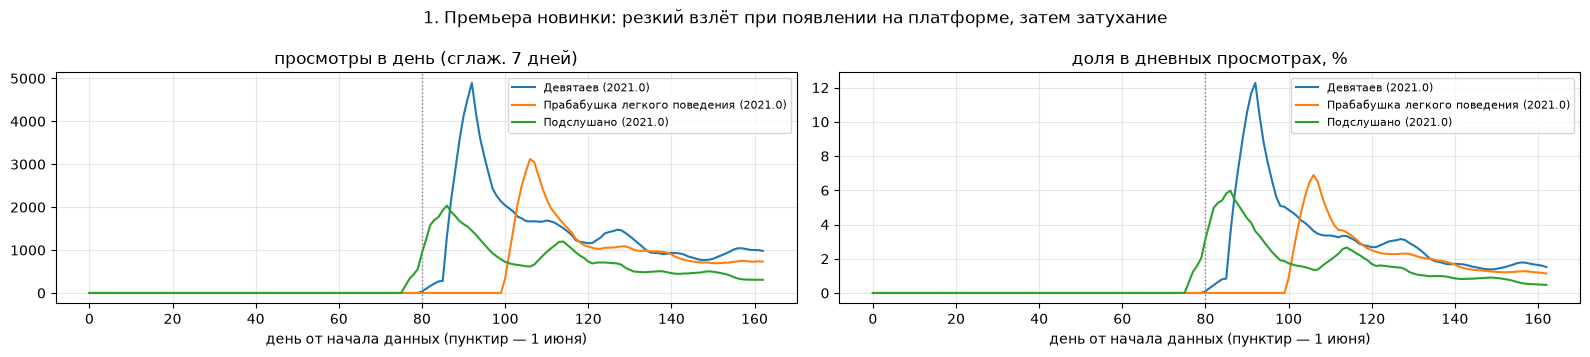

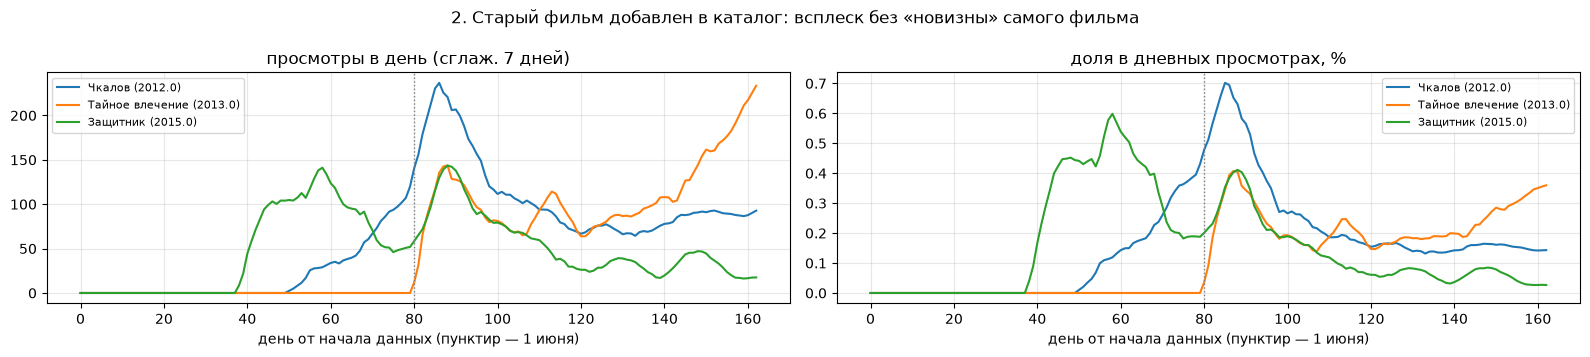

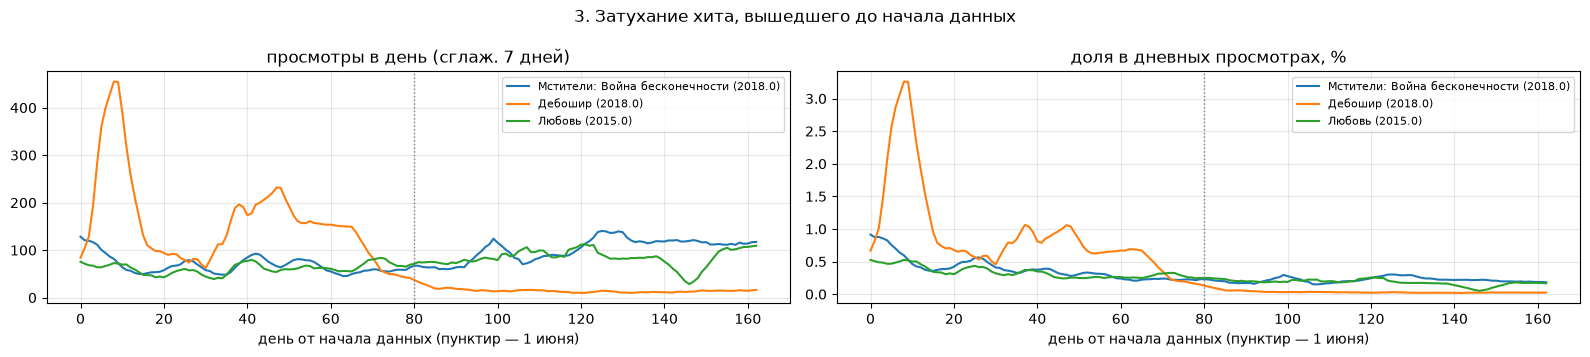

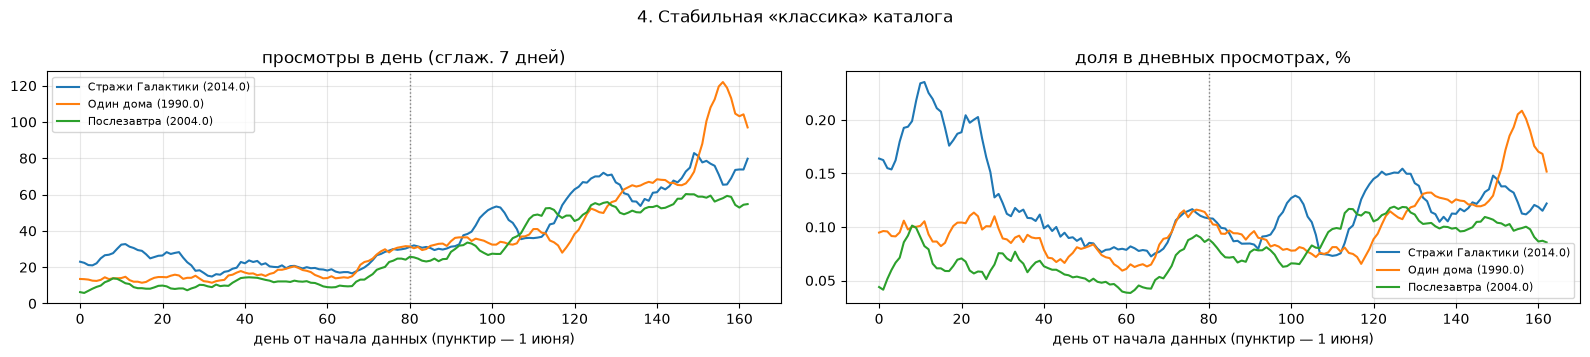

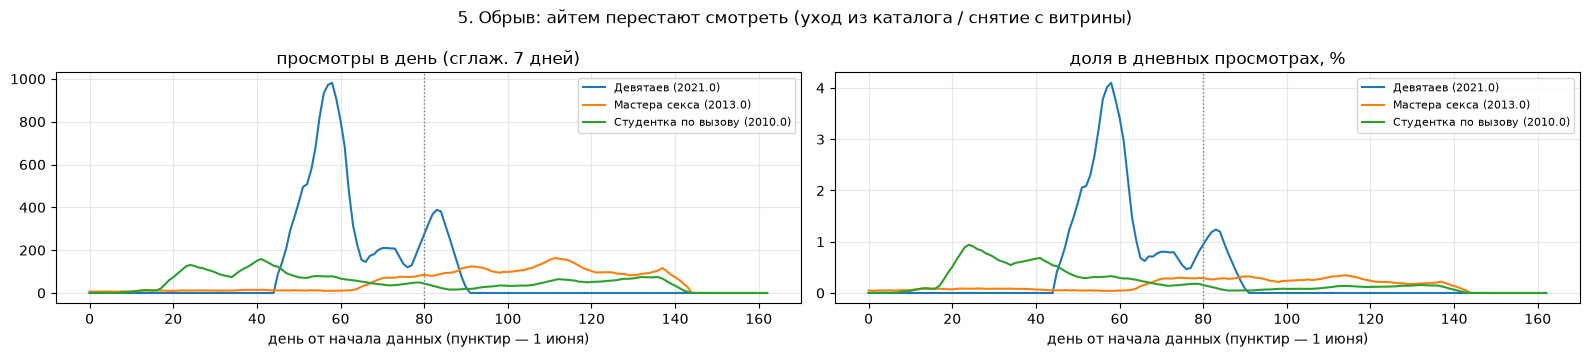

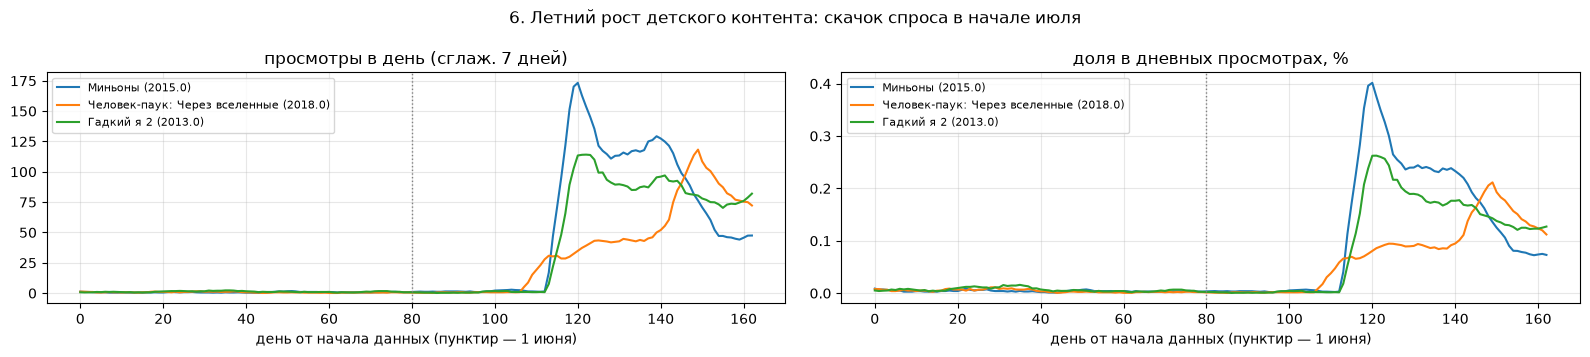

In [33]:
def plot_items(item_ids, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 3.6))
    for i in item_ids:
        label = f'{item_title.get(i, i)} ({item_year.get(i, "")})'
        axes[0].plot(daily.columns, daily.loc[i].rolling(7, min_periods=1, center=True).mean(), label=label)
        axes[1].plot(share.columns, smooth.loc[i] * 100, label=label)
    axes[0].set_title('просмотры в день (сглаж. 7 дней)'); axes[1].set_title('доля в дневных просмотрах, %')
    for ax in axes:
        ax.axvline(DAY_JUNE_1, color='gray', ls=':', lw=1)
        ax.set_xlabel('день от начала данных (пунктир — 1 июня)'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()

for name, d in patterns.items():
    plot_items(d.index[:3], name)

**Как искали.** Взяли 300 самых популярных айтемов и для каждого посчитали долю в дневных просмотрах: абсолютные числа растут вместе со всей аудиторией сервиса, а доля это убирает. Сгладили по неделе, нормировали к максимуму и кластеризовали формы кривых KMeans (7 кластеров). Кластеры показали, какие формы бывают в принципе. Дальше по статистикам кривых (день появления, день пика, последний день просмотров, коэффициент вариации, тренд, год выпуска, доля после 1 июня) задали явные правила для каждого паттерна и взяли самые яркие примеры. День 0 — 13.03.2021, пунктир на графиках — 1 июня (день 80).

**Найденные паттерны**
1. **Премьера новинки** — «Девятаев» (фильм), «Прабабушка лёгкого поведения», «Подслушано», «Афера» (все 2021 года). До появления на платформе просмотров нет, затем за 3–10 дней резкий взлёт к пику и плавное затухание с длинным хвостом. Это эффект релиза: промо на главной, баннеры и сарафанное радио сначала собирают отложенный спрос, а потом интерес гаснет.
2. **Старый фильм/сериал впервые добавлен в каталог** — «Чкалов» (сериал, 2012), «Тайное влечение» (2013), «Защитник» (2015). Кривая та же, что у премьеры, но самому тайтлу 6–9 лет: для пользователей сервиса это «новинка каталога» (новая лицензия), и её продвигают так же, как свежий релиз. У «Тайного влечения» после первой волны идёт второй рост — похоже на повторное продвижение или работу рекомендаций.
3. **Затухание хита, вышедшего до начала данных** — «Мстители: Война бесконечности», «Дебошир», «Непосредственно Каха». Пик в первые дни наблюдений, дальше устойчивый спад доли. Это «хвост» волны, которая началась ещё до марта: кто хотел, тот посмотрел, и тайтл уступает место новинкам. Отсюда же видно, почему популярность за весь период хуже свежей (задание 2).
4. **Стабильная «классика» каталога** — «Стражи Галактики», «Один дома», «Послезавтра», «Король Лев». Низкая вариативность (cv ≈ 0.25–0.32), доля держится на одном уровне все 5 месяцев. Это фильмы, которые пересматривают и ищут по названию независимо от промо. Для них популярность за длинное окно — честная оценка.
5. **Обрыв: айтем перестают смотреть** — «Студентка по вызову», «Мастера секса» и «Остров проклятых»: просмотры обрываются около 140-го дня и больше не появляются, у «Мастеров секса» — на пике интереса. Похоже на окончание лицензии или снятие с витрины (как в примере с «1917»: его просмотры обрываются 5–6 мая 2021 — со ~130 в день до единиц, см. ячейку после примера). Отдельный интересный случай — «Девятаев»: у карточки-**сериала** (id 7107) просмотры обрываются на 87-м дне, а с 83-го появляется карточка-**фильм** (id 13865, паттерн 1). Тот же контент перевели в другую карточку, и для рекомендаций это два разных айтема — классическая проблема дублей в каталоге.
6. **Летний рост детского контента — скачком в начале июля.** Отбор был по росту доли после 1 июня; на графиках видно, что рост не плавный, а ступенькой. «Миньоны» и «Гадкий я 2» (одна франшиза) есть в каталоге с начала данных почти без просмотров, а в начале июля (день ≈ 112–117) одновременно и скачком выходят на 100–175 просмотров в день. Синхронность говорит о событии на стороне сервиса — вероятно, добавлении в подписку или детскую подборку на летние каникулы, — а не о естественном росте интереса. «Человек-паук: Через вселенные» из этой же группы растёт иначе: плавнее, с ~107-го дня, со вторым пиком около 149-го.

Эти паттерны важны для рекомендательной системы: учитывать новизну айтема (1, 2), брать короткие окна популярности (3), не рекомендовать недоступное (5), склеивать дубли карточек (5) и учитывать сезонность и промо (6).

**Задание №5. User-item encoding**

Теперь, создайте матрицу интеракций user-item по примеру из семинара. Вам нужно в итоге получить разреженную матрицу (sparse matrix), в которой в качестве строк будут пользователи, в качестве колонок - айтемы. Не забудьте перекодировать пользователей и айтемы через энкодер. В отличие от семинара, оставьте в матрице только юзеров и айтемы, которые встречались в матрице > 4 раз.

Важно: когда вы отфильтруете юзеров на встречаемость > 4 раз, вы удалите какие-то айтемы, которые теперь станут встречаться меньше 5 раз. Поэтому у вас перестанет выполняться второе условие на минимальное число интеракций с айтемом. Тогда вам надо опять отфильтровать айтемы на встречаемость, но это снова может нарушить условие для юзеров. В таком случае, вам надо написать итеративный алгоритм до сходимости, пока требования не будут выполняться в обеих колонках. 

In [34]:
def filter_column(df, min_freq, col):
    """
    Оставляет только строки, где значение col встречается не меньше min_freq раз.
    Return a copy of the dataframe
    """
    counts = df[col].value_counts()
    keep = counts.index[counts >= min_freq]
    return df[df[col].isin(keep)].copy()

def filter_dataframe(df, cols, min_freq=5):
    """
    Filter dataframe by given columns until each of them satisfies
    min_freq condition, guaranteed by filter_columns. Return a copy
    of the dataframe
    """
    df = df.copy()
    while True:
        n_before = len(df)
        for col in cols:
            df = filter_column(df, min_freq, col)
        if len(df) == n_before:          # сошлось: фильтры больше ничего не удаляют
            break
    return df

filtered_train = filter_dataframe(train_df, ['user_id', 'item_id'], min_freq=5)
assert filtered_train.user_id.value_counts().min() >= 5 and filtered_train.item_id.value_counts().min() >= 5
print('Было:', train_df.shape, train_df.user_id.nunique(), 'юзеров', train_df.item_id.nunique(), 'айтемов')
print('Стало:', filtered_train.shape, filtered_train.user_id.nunique(), 'юзеров', filtered_train.item_id.nunique(), 'айтемов')

Было: (121585, 5) 10000 юзеров 6993 айтемов
Стало: (105402, 5) 5875 юзеров 3005 айтемов


In [35]:
def df_encode(df):
    df = df.copy()
    item2id = {k:v for v, k in enumerate(df.item_id.unique())}
    user2id = {k:v for v, k in enumerate(df.user_id.unique())}   # в шаблоне здесь был item_id — исправлено

    id2item = {k:v for v, k in item2id.items()}
    id2user = {k:v for v, k in user2id.items()}

    df['user_id'] = df.user_id.map(user2id)
    df['item_id'] = df.item_id.map(item2id)
    return df, user2id, item2id, id2user, id2item

filtered_train, user2id, item2id, id2user, id2item = df_encode(filtered_train)
filtered_train.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
1382069,3982,317,47,126,3.0
3729744,1192,2817,22,3226,62.0
356231,746,356,81,7073,100.0
2550645,3526,486,152,4257,52.0
3942774,1888,446,130,1426,23.0


In [36]:
from scipy import sparse as sps

def build_matrix(encoded_df, n_users, n_items):
    return sps.coo_matrix(
        (np.ones(encoded_df.shape[0]), (encoded_df['user_id'], encoded_df['item_id'])),
        shape=(n_users, n_items),
    )

matrix = build_matrix(filtered_train, len(user2id), len(item2id))
matrix

<COOrdinate sparse matrix of dtype 'float64'
	with 105402 stored elements and shape (5875, 3005)>

**Задание №6. Интеракции и частота**

Постройте график зависимости количества айтемов и юзеров от значений (порогов) фильтров на встречаемость в матрице интеракций. То есть, нужно выполнить задание №5 для нескольких значений `min_freq` и построить график зависимости числа оставшихся айтемов и юзеров от этого параметра. 

  0%|          | 0/30 [00:00<?, ?it/s]

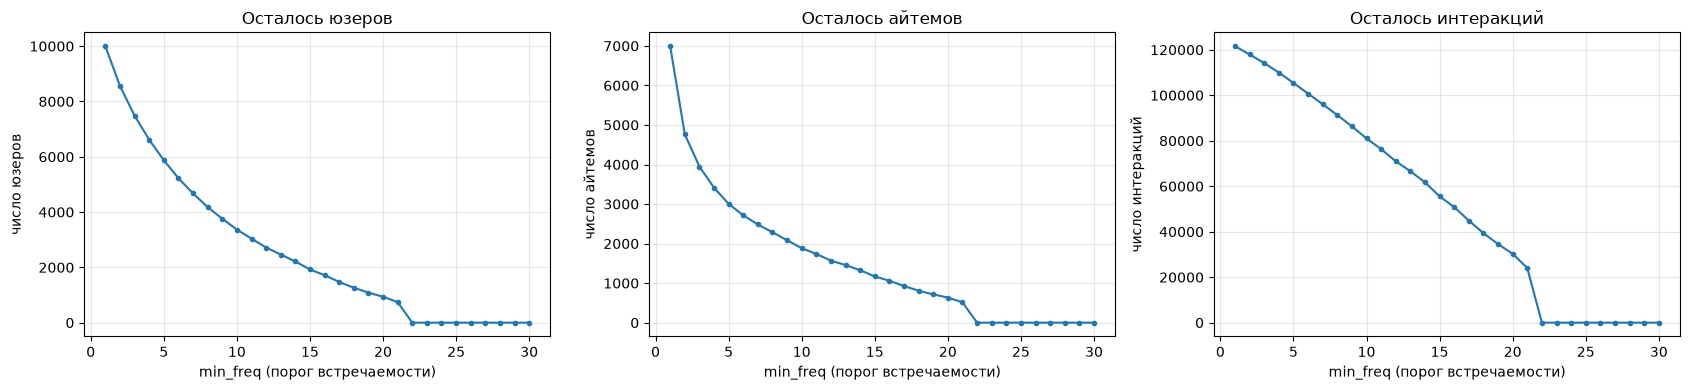

,users,items,interactions
min_freq,,,
1,10000,6993,121585
2,8560,4765,117929
3,7485,3948,114160
5,5875,3005,105402
10,3368,1883,81024
15,1924,1170,55550
20,938,635,30274
30,0,0,0


In [37]:
freq_stats = []
for min_freq in tqdm(range(1, 31)):
    f = filter_dataframe(train_df, ['user_id', 'item_id'], min_freq=min_freq)
    freq_stats.append({'min_freq': min_freq, 'users': f.user_id.nunique(), 'items': f.item_id.nunique(), 'interactions': len(f)})
freq_stats = pd.DataFrame(freq_stats).set_index('min_freq')

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col, name in zip(axes, ['users', 'items', 'interactions'], ['юзеров', 'айтемов', 'интеракций']):
    ax.plot(freq_stats.index, freq_stats[col], marker='o', ms=3)
    ax.set_xlabel('min_freq (порог встречаемости)'); ax.set_ylabel(f'число {name}'); ax.grid(alpha=0.3)
    ax.set_title(f'Осталось {name}')
plt.tight_layout(); plt.show()
freq_stats.loc[[1, 2, 3, 5, 10, 15, 20, 30]]

**Задание №7. EASE**

Реализуйте EASE, постройте рекомендации для юзеров. Сравните все имплементированные ранее метрики качества с `TopPopular` для некоторого набора k. 

Реализацию можно взять из семинара. Можно реализовать по статье https://arxiv.org/pdf/1905.03375.pdf. Можно взять и адаптировать из RecBole https://github.com/RUCAIBox/RecBole.

In [38]:
%%time

# Обучаем конечную модель
# Closed-form решение EASE (Steck, 2019): B = I - P * diag(1 / diag(P)), P = (X^T X + lambda I)^-1, diag(B) = 0
def fit_ease(X, reg_weight=1000):

    X = sps.csr_matrix(X, dtype=np.float64)
    G = (X.T @ X).toarray()                     # матрица Грама айтемов
    diag = np.diag_indices(G.shape[0])
    G[diag] += reg_weight
    P = np.linalg.inv(G)
    B = P / (-np.diag(P))                       # B_ij = -P_ij / P_jj
    B[diag] = 0

    return B

w = fit_ease(matrix)

CPU times: user 445 ms, sys: 50.1 ms, total: 495 ms
Wall time: 297 ms


Далее, вам надо реализовать функцию получения предсказаний. У вас есть обученная матрица весов, которую можно использовать для получения предсказаний. Для этого нужно построить вектор интеракций пользователя и умножить его на матрицу весов.

In [39]:
toppop_list = toppop.recommenations   # для пользователей, у которых нет ни одного айтема из матрицы

def get_preds(x, item2id, id2item, W=None, topn=100):
    W = w if W is None else W
    idx = list({item2id[item] for item, _ in x if item in item2id})
    if len(idx) == 0:                                   # холодный для EASE пользователь
        return toppop_list[:topn]
    scores = W[idx].sum(axis=0)                         # x_u @ B для бинарного вектора интеракций
    scores[idx] = -np.inf                               # не рекомендуем уже просмотренное
    n = min(topn, len(scores) - len(idx))
    top = np.argpartition(-scores, n - 1)[:n]
    top = top[np.argsort(-scores[top])]
    decoded = [id2item[i] for i in top]

    return decoded


joined['ease_preds'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item))
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs,tmp_recs,ease_preds
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[15297, 3734, 2657, 9996, 4151, 8636, 4880, 14..."
1,299,"[(1154, 1), (3208, 40), (12671, 40), (16390, 4...","[(10440, 153)]","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[10440, 3734, 4880, 142, 9996, 12192, 8636, 68..."
2,571,"[(7149, 0), (10169, 5), (5931, 11), (4606, 11)...","[(4567, 156), (3071, 157), (14461, 159), (212,...","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[15297, 13865, 9728, 3734, 4151, 2657, 9996, 4..."
3,684,"[(11237, 36), (3309, 42), (7417, 42), (5658, 4...","[(341, 162)]","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[15297, 3734, 10440, 142, 13865, 9728, 8636, 1..."
4,696,"[(8636, 71), (14741, 71), (9996, 72), (14, 73)...","[(8171, 154)]","[548, 3343, 8793]","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 3734, 4151, 4880, ...","[3734, 2657, 4880, 12192, 6809, 7829, 14703, 4..."


In [40]:
def ease_predict_batch(df, W, item2id, id2item, topn=100, col='train_interactions'):
    """То же, что get_preds, но матрично для всех пользователей сразу (быстро для тюнинга)."""
    rows, cols = [], []
    for r, x in enumerate(df[col]):
        for item, _ in x:
            if item in item2id:
                rows.append(r); cols.append(item2id[item])
    X = sps.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(df), W.shape[0]))
    X.data[:] = 1.0
    scores = X @ W
    scores[X.nonzero()] = -np.inf
    n = min(topn, W.shape[0] - 1)
    top = np.argpartition(-scores, n - 1, axis=1)[:, :n]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1), axis=1)
    id2item_arr = np.array([id2item[i] for i in range(len(id2item))])
    has_items = np.asarray(X.sum(axis=1)).ravel() > 0
    return [list(id2item_arr[t]) if h else toppop_list[:topn] for t, h in zip(top, has_items)]

# проверка: матричный вариант совпадает с get_preds (сравниваем топ-10; при равных скорах порядок может отличаться)
batch_check = ease_predict_batch(joined.head(500), w, item2id, id2item)
same = np.mean([a[:10] == list(b[:10]) for a, b in zip(batch_check, joined.head(500).ease_preds)])
print(f'Совпадение топ-10 у get_preds и ease_predict_batch: {same:.1%}')
assert same > 0.95

Совпадение топ-10 у get_preds и ease_predict_batch: 100.0%


Метрики при k = n_u (topn не задан):


                  map     mrr      hr
TopPopular     0.0360  0.0832  0.1439
EASE (λ=1000)  0.0565  0.1242  0.1852


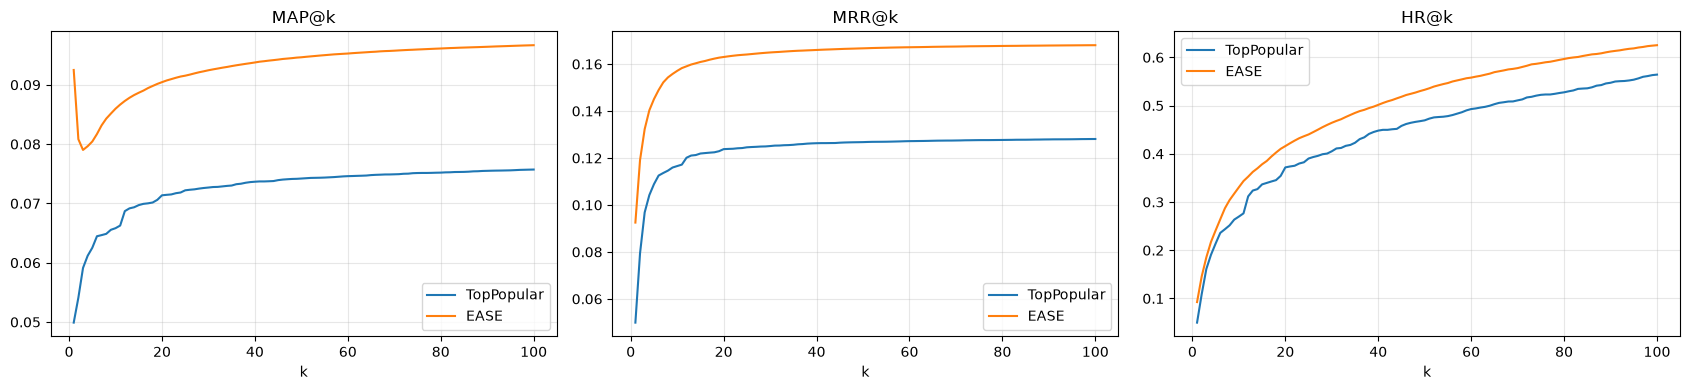

TopPopular                 EASE (λ=1000)                
           map     mrr      hr           map     mrr      hr
k                                                           
1       0.0499  0.0499  0.0499        0.0925  0.0925  0.0925
3       0.0591  0.0968  0.1612        0.0790  0.1323  0.1853
5       0.0625  0.1089  0.2140        0.0804  0.1451  0.2412
10      0.0658  0.1166  0.2698        0.0860  0.1571  0.3306
20      0.0714  0.1238  0.3718        0.0904  0.1630  0.4160
50      0.0742  0.1268  0.4694        0.0946  0.1667  0.5328
100     0.0757  0.1281  0.5642        0.0967  0.1680  0.6252

In [41]:
ks_table = [1, 3, 5, 10, 20, 50, 100]
ease_curves = metric_curves(joined, 'ease_preds', ks=range(1, 101))
compare = pd.concat({'TopPopular': toppop_curves.loc[ks_table], 'EASE (λ=1000)': ease_curves.loc[ks_table]}, axis=1)
print('Метрики при k = n_u (topn не задан):')
print(pd.DataFrame({'TopPopular': evaluate_recommender(joined, 'toppopular_recs'),
                    'EASE (λ=1000)': evaluate_recommender(joined, 'ease_preds')}).T.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, m, name in zip(axes, ['map', 'mrr', 'hr'], ['MAP@k', 'MRR@k', 'HR@k']):
    ax.plot(toppop_curves.index, toppop_curves[m], label='TopPopular')
    ax.plot(ease_curves.index, ease_curves[m], label='EASE')
    ax.set_xlabel('k'); ax.set_title(name); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
compare.round(4)

Сделайте выводы — какой алгоритм работает лучше?

**Ответ:** EASE лучше TopPopular на всех k и по всем трём метрикам (λ = 1000, как в шаблоне). MAP@10 — 0.086 против 0.066, MRR@10 — 0.157 против 0.117, HR@10 — 0.331 против 0.270, HR@100 — 0.625 против 0.564. При k = n_u: MAP 0.057 против 0.036, MRR 0.124 против 0.083. Особенно велик разрыв на первой позиции: доля «попаданий первым айтемом» почти вдвое выше (0.093 против 0.050). Причины две: EASE персонализирует выдачу по истории пользователя и не рекомендует уже просмотренное. При этом TopPopular остаётся сильным бейзлайном: KION — сервис с очень концентрированным спросом на новинки, и EASE во многом выучивает ту же популярность, но в пересчёте на конкретного пользователя.

**Задание №8. Тюнинг**

Переберите различные значения гиперпараметра коэффициента регуляризации у EASE и постройте графики, как в задании №6. Постарайтесь "затюнить" EASE как можно лучше. Возьмите разумное число гиперпараметров - хотя бы штук 20 по логарифмической сетке, либо используйте более хитрые алгоритмы оптимизации. 

In [42]:
%%time
reg_grid = np.logspace(-1, 5, 25)          # 25 значений по логарифмической сетке от 0.1 до 1e5
tuning = []
for reg in tqdm(reg_grid):
    start = time.perf_counter()
    W_reg = fit_ease(matrix, reg_weight=reg)
    fit_time = time.perf_counter() - start
    joined['tmp_recs'] = ease_predict_batch(joined, W_reg, item2id, id2item, topn=100)
    curves = metric_curves(joined, 'tmp_recs', ks=[10, 100])
    nu = evaluate_recommender(joined, 'tmp_recs')
    tuning.append({'reg': reg, 'fit_time': fit_time,
                   'map@10': curves.loc[10, 'map'], 'mrr@10': curves.loc[10, 'mrr'], 'hr@10': curves.loc[10, 'hr'],
                   'hr@100': curves.loc[100, 'hr'], 'map@n_u': nu['map'], 'mrr@n_u': nu['mrr'], 'hr@n_u': nu['hr'],
                   'w_abs_mean': np.abs(W_reg).mean(), 'w_max': np.abs(W_reg).max()})
tuning = pd.DataFrame(tuning).set_index('reg')
best_reg = tuning['map@10'].idxmax()
print(f'Лучшее λ по MAP@10: {best_reg:.1f}')
tuning.round(4)

  0%|          | 0/25 [00:00<?, ?it/s]

Лучшее λ по MAP@10: 10000.0
CPU times: user 31.5 s, sys: 332 ms, total: 31.8 s
Wall time: 27.1 s


,fit_time,map@10,mrr@10,hr@10,hr@100,map@n_u,mrr@n_u,hr@n_u,w_abs_mean,w_max
reg,,,,,,,,,,
0.100000,0.2581,0.0648,0.1206,0.2507,0.4865,0.0443,0.0970,0.1470,0.0201,1.4764
0.177828,0.2558,0.0652,0.1216,0.2530,0.4899,0.0444,0.0975,0.1475,0.0187,1.3150
0.316228,0.2489,0.0657,0.1228,0.2556,0.4927,0.0444,0.0983,0.1485,0.0170,1.1147
0.562341,0.2497,0.0667,0.1243,0.2587,0.4987,0.0452,0.0996,0.1511,0.0150,0.8938
1.000000,0.2502,0.0680,0.1266,0.2651,0.5025,0.0459,0.1011,0.1534,0.0129,0.6789
1.778279,0.2501,0.0699,0.1302,0.2732,0.5080,0.0470,0.1040,0.1591,0.0108,0.6305
3.162278,0.2506,0.0718,0.1343,0.2822,0.5161,0.0483,0.1075,0.1646,0.0089,0.5960
5.623413,0.2546,0.0737,0.1382,0.2894,0.5242,0.0498,0.1108,0.1691,0.0071,0.5515
10.000000,0.2506,0.0760,0.1422,0.2959,0.5350,0.0514,0.1145,0.1742,0.0056,0.4969


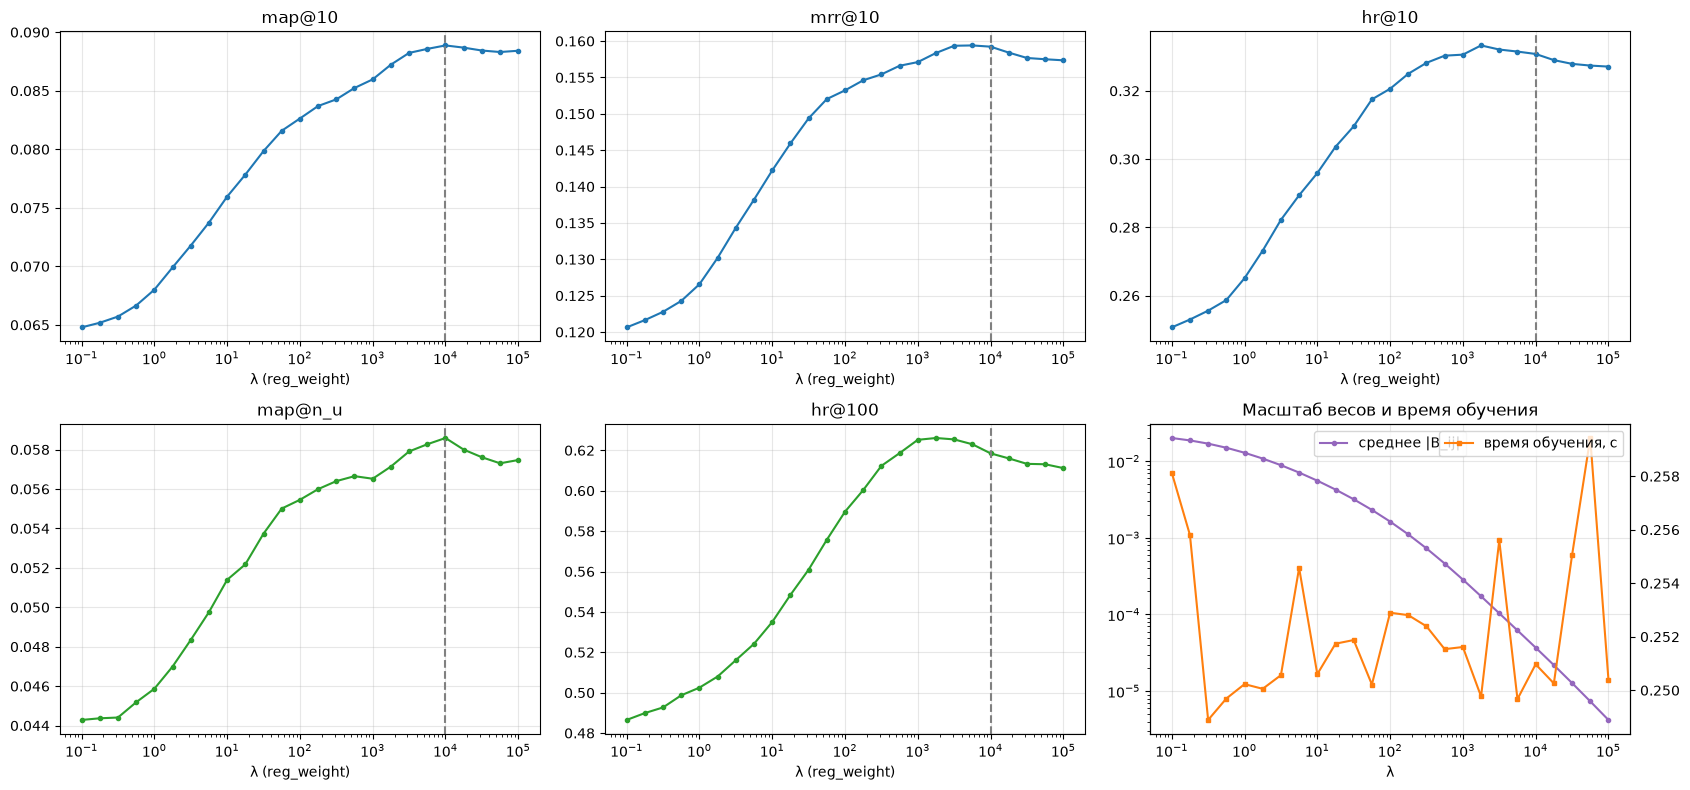

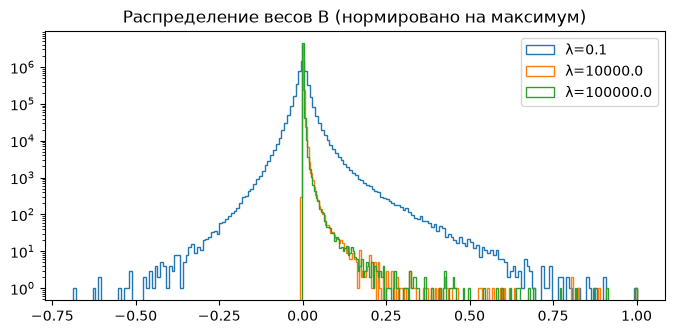

TopPopular                 EASE λ=1000                 EASE λ=10000  \
           map     mrr      hr         map     mrr      hr          map   
k                                                                         
1       0.0499  0.0499  0.0499      0.0925  0.0925  0.0925       0.0930   
3       0.0591  0.0968  0.1612      0.0790  0.1323  0.1853       0.0830   
5       0.0625  0.1089  0.2140      0.0804  0.1451  0.2412       0.0840   
10      0.0658  0.1166  0.2698      0.0860  0.1571  0.3306       0.0889   
20      0.0714  0.1238  0.3718      0.0904  0.1630  0.4160       0.0931   
50      0.0742  0.1268  0.4694      0.0946  0.1667  0.5328       0.0969   
100     0.0757  0.1281  0.5642      0.0967  0.1680  0.6252       0.0989   

                     
        mrr      hr  
k                    
1    0.0930  0.0930  
3    0.1362  0.1939  
5    0.1482  0.2461  
10   0.1592  0.3308  
20   0.1646  0.4090  
50   0.1682  0.5209  
100  0.1696  0.6185

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, m in zip(axes[0], ['map@10', 'mrr@10', 'hr@10']):
    ax.plot(tuning.index, tuning[m], marker='o', ms=3)
    ax.axvline(best_reg, color='gray', ls='--')
    ax.set_xscale('log'); ax.set_xlabel('λ (reg_weight)'); ax.set_title(m); ax.grid(alpha=0.3)
for ax, m in zip(axes[1][:2], ['map@n_u', 'hr@100']):
    ax.plot(tuning.index, tuning[m], marker='o', ms=3, color='tab:green')
    ax.axvline(best_reg, color='gray', ls='--')
    ax.set_xscale('log'); ax.set_xlabel('λ (reg_weight)'); ax.set_title(m); ax.grid(alpha=0.3)
ax = axes[1][2]
ax.plot(tuning.index, tuning['w_abs_mean'], marker='o', ms=3, color='tab:purple', label='среднее |B_ij|')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('λ'); ax.grid(alpha=0.3)
ax2 = ax.twinx(); ax2.plot(tuning.index, tuning['fit_time'], color='tab:orange', marker='s', ms=3, label='время обучения, с')
ax.set_title('Масштаб весов и время обучения'); ax.legend(loc='upper center'); ax2.legend(loc='upper right')
plt.tight_layout(); plt.show()

# распределение весов при маленьком, лучшем и большом λ
fig, ax = plt.subplots(figsize=(8, 3.5))
for reg in [reg_grid[0], best_reg, reg_grid[-1]]:
    W_reg = fit_ease(matrix, reg_weight=reg)
    vals = W_reg[np.triu_indices_from(W_reg, 1)]
    ax.hist(vals / np.abs(vals).max(), bins=200, histtype='step', log=True, label=f'λ={reg:.1f}')
ax.set_title('Распределение весов B (нормировано на максимум)'); ax.legend(); plt.show()

w_best = fit_ease(matrix, reg_weight=best_reg)
joined['ease_best_preds'] = ease_predict_batch(joined, w_best, item2id, id2item, topn=100)
ease_best_curves = metric_curves(joined, 'ease_best_preds')
pd.concat({'TopPopular': toppop_curves.loc[ks_table], 'EASE λ=1000': ease_curves.loc[ks_table],
           f'EASE λ={best_reg:.0f}': ease_best_curves.loc[ks_table]}, axis=1).round(4)

Ответьте на следующие вопросы:

**8.1 Какое значение гиперпараметра является наилучшим?**

**Ответ:** (λ, как и в задании, подбирался по тестовым метрикам — это оптимистичная оценка) по MAP@10 лучшее λ ≈ **10 000** (MAP@10 = 0.0889, MAP@n_u = 0.0586). Оптимум плоский: на всём диапазоне λ ∈ [3 000; 30 000] MAP@10 держится около 0.088–0.089. По HR@10 и HR@100 оптимум чуть левее, λ ≈ 1 800 (HR@100 = 0.626). Компромиссом можно считать λ ≈ 3 000–10 000. Матрица маленькая (5 875 × 3 005), поэтому оптимальная регуляризация большая — на порядок больше значения 1000 из шаблона.

**8.2 Что ещё интересного можно сказать по графикам?**

**Ответ:**
* **Малые λ (0.1–10) явно хуже**: MAP@10 ≈ 0.065–0.076. Веса большие (max |B| ≈ 1.5 при λ = 0.1) и шумные: модель переобучается на случайные совместные просмотры редких айтемов.
* **Большие λ** сжимают все веса. Решение стремится к B ≈ XᵀX / λ — обычному item-item по числу совместных просмотров, которое смещено к популярному. Поэтому после ~10⁴ метрики начинают медленно падать (ещё немного, и получится почти TopPopular).
* **Разные метрики реагируют по-разному**: метрики верха списка (MAP@10, MRR@10) любят более сильную регуляризацию, HR@100 — более слабую. Сильная регуляризация лучше упорядочивает верх выдачи популярными «безопасными» айтемами, слабая — даёт больше разнообразия глубже в списке.
* **Распределение весов**: при малых λ хвосты распределения тяжёлые в обе стороны (много больших отрицательных весов), при больших — распределение сжато около нуля.
* **Скорость тюнинга**: время обучения ≈ 0.25 с (на M3 Max) и от λ не зависит — всё время уходит на обращение матрицы n_items × n_items, O(n³). Перебрать 25 значений дёшево, основное время тюнинга уходит на построение предсказаний и подсчёт метрик. Значения можно было бы считать ещё быстрее: собственное разложение XᵀX делается один раз, а потом (XᵀX + λI)⁻¹ пересчитывается для любого λ без нового обращения.

**Задание №9. EASE и topk**

В лекции №2 говорилось, что качество у EASE растет с ослаблением фильтра на число айтемов. В этом задании постройте кривые метрик качества MAP/MRR/HR в зависимости от topk (например, от 1 до 100 с некоторым шагом), где кривая параметризована минимальным требуемым значением встречаемости user/item (из задания №6). Опишите свои выводы.

Важно: в этом задании линии могут быть мало различимыми, поэтому ваша задача для каждой метрики найти нужный масштаб на каких-то конкретных topk, чтобы линии стали визуально отличимы. 

In [44]:
%%time
min_freqs = [1, 2, 3, 5, 10, 20]
freq_curves, freq_info = {}, []
for min_freq in tqdm(min_freqs):
    f = filter_dataframe(train_df, ['user_id', 'item_id'], min_freq=min_freq)
    f_enc, u2id, i2id, id2u, id2i = df_encode(f)
    X = build_matrix(f_enc, len(u2id), len(i2id))
    W_f = fit_ease(X, reg_weight=best_reg)
    joined['tmp_recs'] = ease_predict_batch(joined, W_f, i2id, id2i, topn=100)
    freq_curves[min_freq] = metric_curves(joined, 'tmp_recs')
    freq_info.append({'min_freq': min_freq, 'users': len(u2id), 'items': len(i2id),
                      'test_items_covered_%': 100 * np.mean([x[0] in i2id for row in joined.test_interactions for x in row])})
freq_info = pd.DataFrame(freq_info).set_index('min_freq')
freq_info.round(2)

  0%|          | 0/6 [00:00<?, ?it/s]

CPU times: user 10.9 s, sys: 463 ms, total: 11.4 s
Wall time: 7.7 s


,users,items,test_items_covered_%
min_freq,,,
1,10000,6993,94.81
2,8560,4765,93.22
3,7485,3948,92.10
5,5875,3005,88.00
10,3368,1883,81.00
20,938,635,58.02


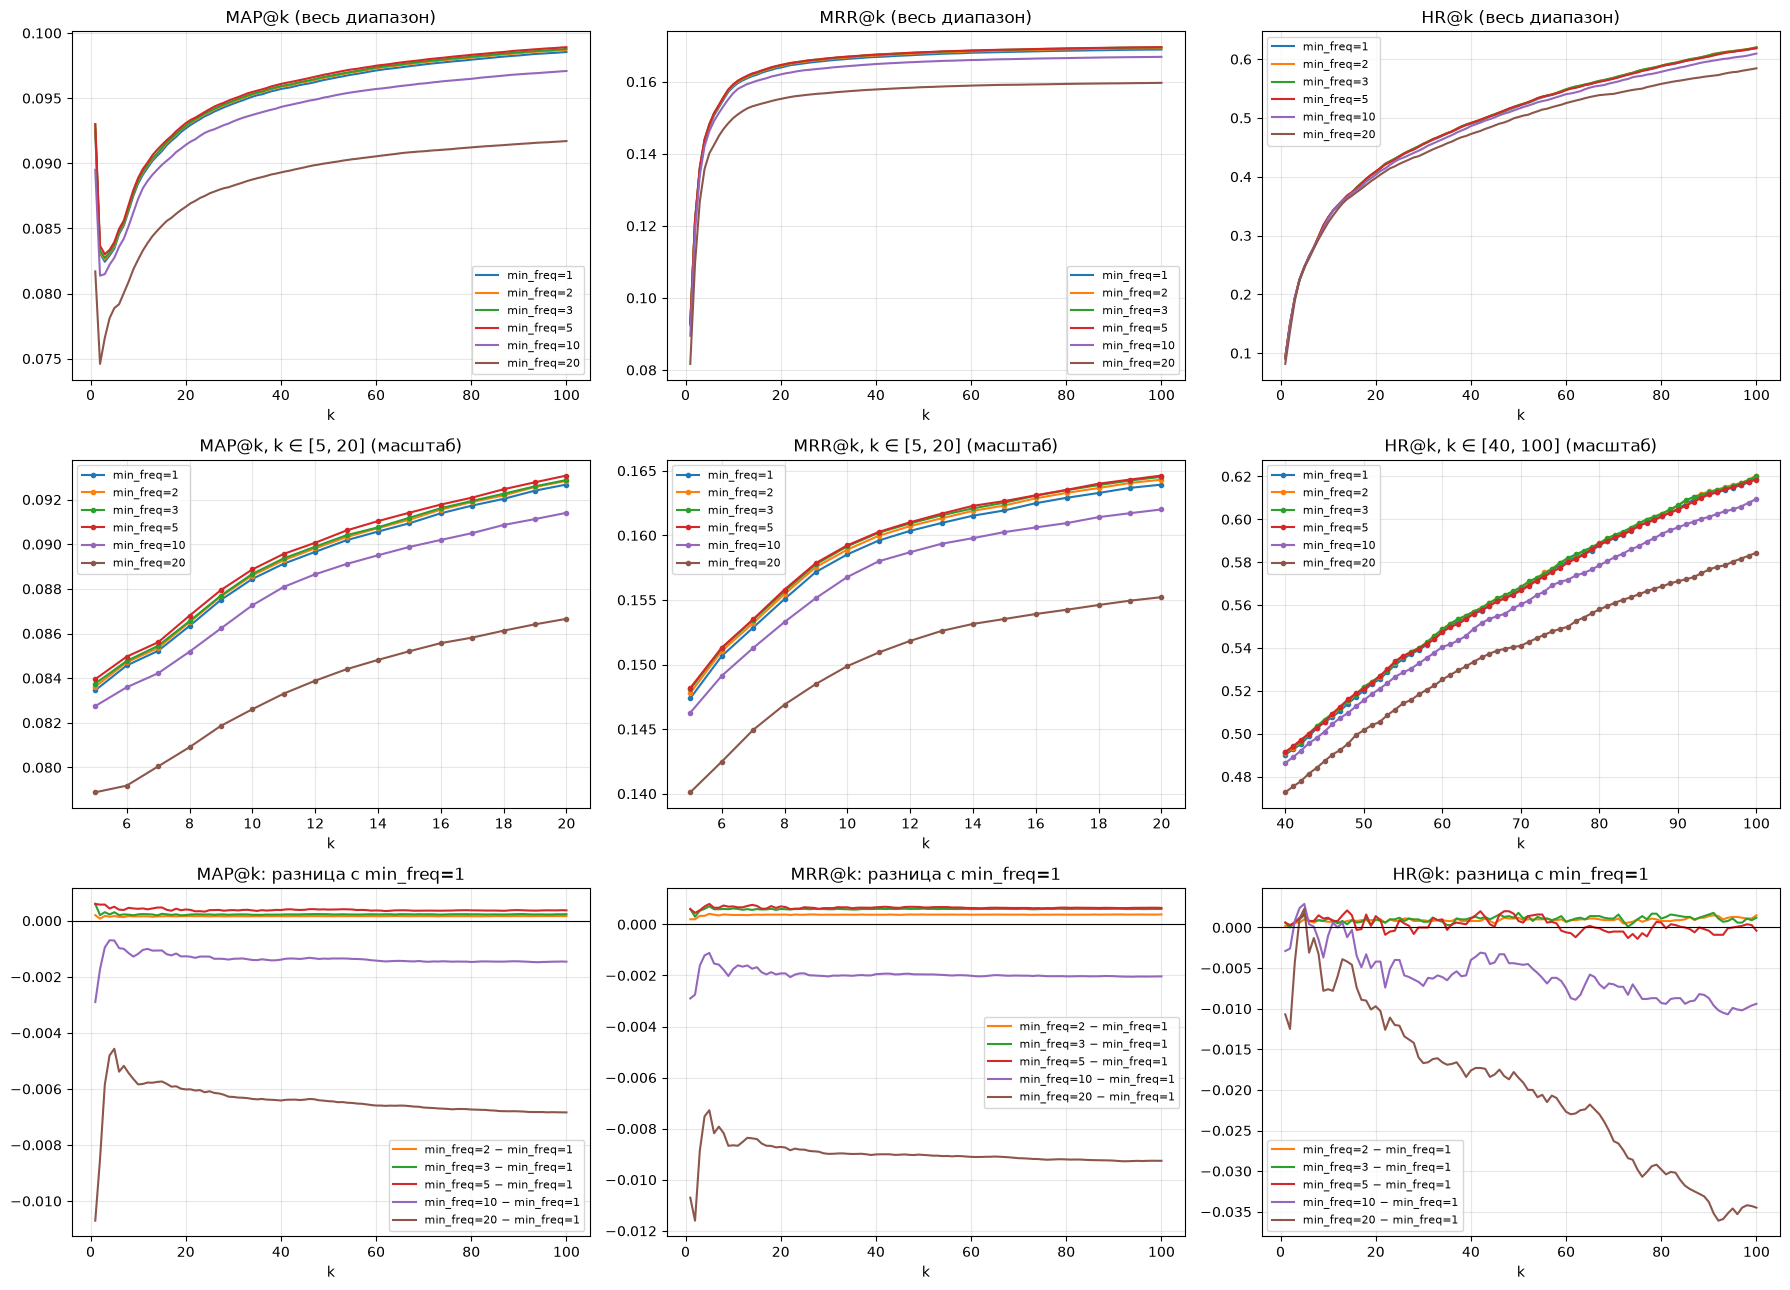

1                       2                       3                   \
        map     mrr      hr     map     mrr      hr     map     mrr      hr   
k                                                                             
1    0.0924  0.0924  0.0924  0.0926  0.0926  0.0926  0.0930  0.0930  0.0930   
5    0.0835  0.1474  0.2444  0.0836  0.1478  0.2454  0.0838  0.1481  0.2459   
10   0.0884  0.1585  0.3296  0.0886  0.1589  0.3303  0.0887  0.1592  0.3307   
20   0.0927  0.1639  0.4076  0.0928  0.1643  0.4085  0.0929  0.1645  0.4086   
50   0.0965  0.1675  0.5201  0.0966  0.1679  0.5213  0.0967  0.1681  0.5219   
100  0.0985  0.1689  0.6189  0.0987  0.1693  0.6204  0.0988  0.1695  0.6201   

         5                       10                      20                  
        map     mrr      hr     map     mrr      hr     map     mrr      hr  
k                                                                            
1    0.0930  0.0930  0.0930  0.0895  0.0895  0.0895  0.0817  0.0817  0.0817  
5    0.0840  0.1482  0.2461  0.0827  0.1463  0.2473  0.0789  0.1401  0.2467  
10   0.0889  0.1592  0.3308  0.0873  0.1568  0.3286  0.0826  0.1499  0.3220  
20   0.0931  0.1646  0.4090  0.0914  0.1620  0.4034  0.0867  0.1552  0.3979  
50   0.0969  0.1682  0.5209  0.0951  0.1656  0.5156  0.0900  0.1585  0.5016  
100  0.0989  0.1696  0.6185  0.0971  0.1669  0.6095  0.0917  0.1597  0.5844

In [45]:
zoom = {'map': (5, 20), 'mrr': (5, 20), 'hr': (40, 100)}
colors = {mf: f'C{n}' for n, mf in enumerate(min_freqs)}   # один цвет на min_freq во всех рядах
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for j, (m, name) in enumerate(zip(['map', 'mrr', 'hr'], ['MAP@k', 'MRR@k', 'HR@k'])):
    for min_freq in min_freqs:
        c = freq_curves[min_freq][m]
        axes[0, j].plot(c.index, c.values, label=f'min_freq={min_freq}', color=colors[min_freq])
        lo, hi = zoom[m]
        axes[1, j].plot(c.loc[lo:hi].index, c.loc[lo:hi].values, marker='o', ms=3, label=f'min_freq={min_freq}', color=colors[min_freq])
    axes[0, j].set_title(name + ' (весь диапазон)'); axes[1, j].set_title(f'{name}, k ∈ [{zoom[m][0]}, {zoom[m][1]}] (масштаб)')
    base = freq_curves[1][m]
    for min_freq in min_freqs[1:]:      # разница с min_freq=1 — так близкие линии становятся различимы
        axes[2, j].plot(base.index, freq_curves[min_freq][m] - base, label=f'min_freq={min_freq} − min_freq=1', color=colors[min_freq])
    axes[2, j].axhline(0, color='black', lw=0.8)
    axes[2, j].set_title(f'{name}: разница с min_freq=1')
    for ax in axes[:, j]:
        ax.set_xlabel('k'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

pd.concat({mf: freq_curves[mf].loc[[1, 5, 10, 20, 50, 100]] for mf in min_freqs}, axis=1).round(4)

Что вы можете сказать на основе полученных графиков? Соответствуют ли они вашим ожиданиям?

**Ответ:**
* Ослабление фильтра с 20 до 10 и с 10 до 5 даёт **большой** прирост на всех k: MAP@10 — 0.083 → 0.087 → 0.089, HR@100 — 0.584 → 0.610 → 0.619. Жёсткий фильтр выкидывает айтемы, которые пользователи реально смотрят в тесте: при min_freq = 20 в матрице остаётся только 58% тестовых просмотров, при 10 — 81%, при 5 — 88%. Он же выкидывает пользователей, у которых пропадает вектор истории.
* Дальше, от 5 к 1, кривые почти сливаются: разница по MAP и MRR меньше 0.001, по HR — не больше ≈ 0.002 (нижний ряд графиков — разность с min_freq = 1). На верхних позициях (MAP/MRR при k ≤ 20) min_freq = 3–5 даже чуть лучше, чем 1–2. На глубине (HR@k при k ≈ 60–100) min_freq = 1–3 немного выигрывает: редкие айтемы иногда попадают в хвост выдачи.
* Ожиданиям из лекции («качество растёт с ослаблением фильтра») это соответствует **частично**: рост есть, но он насыщается. Покрытие тестовых айтемов растёт медленно (88% → 95%), редкие айтемы почти не встречаются в тесте, а сильная регуляризация (λ = 10⁴) всё равно гасит их веса. При этом матрица растёт с 3 005 до 6 993 айтемов, и обучение (O(n³)) дорожает примерно в 12 раз. Разумный выбор — min_freq ≈ 3–5.

**Задание №10. Интерпретируемые рекомендации**

Используйте выученную матрицу весов для item2item рекомендаций. Приведите 10 примеров топ-5 рекомендаций от EASE к сэмплируемым айтемам. Используйте названия фильмов вместо id при выводе рекомендаций. 

In [46]:
# item2item: для айтема i берём строку B[i, :] — какие айтемы модель предсказывает по факту просмотра i
id2item_best = id2item
item_pop = filtered_train.item_id.value_counts()           # популярность в закодированных id
rng = np.random.default_rng(10)
sampled = rng.choice(item_pop.index[:500], size=10, replace=False)   # из 500 самых популярных в матрице
for enc_item in sampled:
    row = w_best[enc_item]
    top5 = np.argsort(-row)[:5]
    orig = id2item_best[enc_item]
    print(f'\n«{item_title.get(orig, orig)}» ({item_type.get(orig, "")}, {item_year.get(orig, "")}) — {item_pop[enc_item]} просмотров:')
    for j in top5:
        o = id2item_best[j]
        print(f'    {row[j]:+.4f}  {item_title.get(o, o)} ({item_type.get(o, "")}, {item_year.get(o, "")})')


«Стражи Галактики» (film, 2014.0) — 170 просмотров:
    +0.0063  Стражи Галактики. Часть 2 (film, 2017.0)
    +0.0056  Мстители (film, 2012.0)
    +0.0053  Мстители: Финал (film, 2019.0)
    +0.0050  Мстители: Война бесконечности (film, 2018.0)
    +0.0043  Мстители: Эра Альтрона (film, 2015.0)

«Дикая лига» (film, 2019.0) — 55 просмотров:
    +0.0026  Девятаев (film, 2021.0)
    +0.0019  Белый снег (film, 2021.0)
    +0.0015  Хрустальный (series, 2021.0)
    +0.0013  Гнев человеческий (film, 2021.0)
    +0.0011  Маша (film, 2020.0)

«На грани безумия» (film, 2018.0) — 54 просмотров:
    +0.0018  Хрустальный (series, 2021.0)
    +0.0016  Гнев человеческий (film, 2021.0)
    +0.0014  Защитник (film, 2015.0)
    +0.0013  Маша (film, 2020.0)
    +0.0012  Взаперти (film, 2020.0)

«Избави нас от лукавого» (film, 2020.0) — 57 просмотров:
    +0.0022  Гнев человеческий (film, 2021.0)
    +0.0017  Восемь сотен (film, 2020.0)
    +0.0017  Хрустальный (series, 2021.0)
    +0.0015  Дочь волка (f

In [47]:
# Те же айтемы при меньшей регуляризации (λ = 100): веса менее «сглажены» к популярному
w_small = fit_ease(matrix, reg_weight=100)
for enc_item in sampled[:5]:
    orig = id2item[enc_item]
    top5 = np.argsort(-w_small[enc_item])[:5]
    print(f'«{item_title.get(orig, orig)}»: ' + '; '.join(item_title.get(id2item[j], j) for j in top5))

# насколько item2item-выдача смещена к популярному: средняя популярность рекомендованных айтемов
pop_rank = item_pop.rank(ascending=False)
for name, W_ in [(f'λ={best_reg:.0f}', w_best), ('λ=100', w_small)]:
    tops = np.argsort(-W_, axis=1)[:, :5]
    print(f'{name}: медианный ранг популярности item2item-рекомендаций = {np.median(pop_rank.reindex(tops.ravel()).values):.0f}')

«Стражи Галактики»: Стражи Галактики. Часть 2; Мстители; Первый мститель: Другая война; Веном; Мстители: Финал
«Дикая лига»: Белый снег; Девятаев; Коридор бессмертия; Стендап под прикрытием; Фемида видит
«На грани безумия»: Защитник; Отель для самоубийц; Драка в блоке 99; Жена online; Маша
«Избави нас от лукавого»: Клуб «Кастет»; Восемь сотен; Афера по-итальянски; Король лев (2019); Дебошир
«Гарфилд»: Гарфилд 2: История двух кошечек; Рио 2; Храбрая сердцем; Город героев; Тупой и еще тупее 2


λ=10000: медианный ранг популярности item2item-рекомендаций = 25


λ=100: медианный ранг популярности item2item-рекомендаций = 168


Хорошие ли получились рекомендации? Почему? Есть ли хорошие примеры? Есть ли плохие? Почему бывают плохие примеры?

**Ответ:** часть рекомендаций хорошая и понятная, часть — просто популярные новинки.
* **Хорошие примеры**: «Стражи Галактики» → «Стражи Галактики. Часть 2», «Мстители», «Мстители: Финал», «Война бесконечности» — та же вселенная Marvel. «Рататуй» → «Зверополис», «Ральф против Интернета», «Корпорация монстров», «Тайна Коко» — семейная анимация Disney/Pixar. Модель выучила совместное потребление внутри франшиз, жанров и аудиторий.
* **Плохие примеры**: «Дикая лига», «На грани безумия», «Избави нас от лукавого», «Halo: Сумерки» → «Хрустальный», «Гнев человеческий», «Девятаев», «Маша». Это просто самые популярные тайтлы периода, связь с исходным фильмом слабая.
* **Почему так бывает:**
  1. Мало данных: у этих айтемов около 50 просмотров в выборке из 5 875 пользователей, совместных просмотров с похожими фильмами почти нет.
  2. Популярные айтемы встречаются вместе со всем подряд.
  3. Сильная регуляризация (λ = 10⁴) стягивает веса к матрице совместной встречаемости XᵀX / λ, где доминирует популярность. Медианный ранг популярности item2item-рекомендаций при лучшем λ — 25, а при λ = 100 — 168.
  4. При λ = 100 рекомендации заметно специфичнее: «Гарфилд» → «Гарфилд 2», «Стражи Галактики» → «Первый мститель», «Веном». Но в среднем по пользователям метрики хуже — шума больше.
  5. Данные «грязные»: один и тот же контент живёт в разных карточках (сериал и фильм «Девятаев»), а для детских мультфильмов совместные просмотры отражают поведение всей семьи на одном аккаунте.

  Метрики ранжирования оптимизируют попадания, а не «смысловую похожесть». Поэтому лучшая по MAP модель тянется к популярному — и это нормально для бизнес-метрики, но плохо для item2item-витрины «похожие фильмы».